# CU-BEMS Intelligence Suite — Question 1 (Operational Baseload)
## Notebook 1E: Exploratory Data Analysis & Baseload Modeling (`qn1e_eda_and_baseload_modeling.ipynb`)

---

### Core Research Question
> *How can we identify and reduce unnecessary energy consumption outside operating hours across all 7 floors of the Chamchuri 5?*

**Data Scope:** 18 continuous months (July 1, 2018 – December 31, 2019) across 33 lighting zones and 32 plug circuits (65 total electrical sub-meters).

---

### Expected Project Deliverables
1. **01 Waste Map**: A per-circuit, per-floor view of where after-hours baseload runs and how large it is across all 7 floors.
2. **02 Circuit Classification**: Each of the 65 circuits tagged as **Critical Standby** or **Preventable Waste** via unsupervised machine learning.

---

### Methodological Architecture
1. **Operational Schedule Stratification**: Stratify the 18-month timeline into Occupied (Mon–Fri 08:00–17:00, 25.0% of calendar) vs. Unoccupied (Nights, Weekends, 36 statutory Thai National Holidays, 75.0% of calendar).
2. **Empirical Schedule Validation**: Validate the 08:00–17:00 operating window by comparing Weekday vs. Saturday hourly load profiles, demonstrating a sustained +85 kW daytime occupancy surge and evening load decline.
3. **Deep-Night Reference Calibration**: Establish reference baseload during the verified empirical load trough (Sundays 02:00–04:00 AM) across 52 training weeks.
4. **Dynamic Time-of-Week Quantile Formulation ($P_{2.5}(d, h)$)**: Derive dynamic circuit baseload floors using the 2.5th percentile across time-of-week slots ($q=0.025$). This accounts for empirical operational transitions (e.g. evening shoulder departure vs. deep sleep) without absorbing human negligence.
5. **Unsupervised Machine Learning (K-Means, $k=3$)**: Cluster all 65 circuits on five scale-free behaviour features (`Night_On_Frac`, `Base_to_Peak`, `Night_to_Day`, `Weekend_to_Weekday`, `OffHours_CV`) into 24/7 steady, extended-hours/scheduled and occupancy-following loads; the 24/7 group is tagged **Critical Standby** and the other two **Preventable Waste**.
6. **Per-Circuit Spatial Waste Map**: Map after-hours standby loads and preventable schedule surplus across all 7 floors and 65 circuits under the dynamic baseload.
7. **Addressable Energy & Utility Cost Quantification**: Price preventable surplus against official MEA Schedule 3.2 / 4.2 Time-of-Use rates (12-24 kV Tier) (Peak ฿4.3297, Off-Peak ฿2.5849) broken down by building scope, end-use category, and floor (Floors 1 to 7).
8. **Digital Twin Synchronization**: Export the dynamic baseload matrix and classification registry directly to the building intelligence webapp and digital twin platform.

---

### Core Modeling Assumptions & Boundary Conditions
1. **Zero-Power Metrology Integrity**: A reading of `0.000 kW` represents a genuine physically de-energized circuit ($I = 0\text{ A}$), not missing data. True telemetry loss registers as `NaN` and is preserved without artificial interpolation.
2. **Schedule & Telemetry Occupancy Inference**: With no turnstile or RFID badge-swipe telemetry available, occupancy is inferred from facility operating hours (Monday–Friday 08:00–17:00), 36 statutory Bank of Thailand public holidays, and physically verified via daytime plug-load step changes (+85 kW surge).
3. **Reference Calibration Window**: Sunday 02:00–04:00 AM represents the verified empirical weekly load trough (~79.0 kW), capturing steady-state overnight load including timer-driven exterior lighting.
4. **Dynamic Non-Parametric Estimator ($P_{2.5}$)**: The 2.5th percentile across time-of-week slots accounts for physical departure gradients while providing a robust annual buffer against transient dropouts.
5. **Operational Waste vs. Hardware Faults**: Flagged after-hours loads represent **potential operational waste** (functional equipment left energized in unoccupied spaces), not confirmed hardware faults or physical electrical defects.
6. **Conservative Tariff Valuation**: Savings are evaluated strictly on energy-only MEA Schedule 4.2 TOU rates, excluding peak demand surcharges and Ft fees, broken down across the 59 curfew-eligible circuits while protecting the 6 K-Means-identified critical standby circuits.


In [1]:
# ==============================================================================
# 1. ENVIRONMENT & DIRECTORY CONFIGURATION
# ==============================================================================
import os, glob, json, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, time

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

data_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'data')) if os.path.basename(os.getcwd()) == 'notebooks' else os.path.join(os.getcwd(), 'data')

# Ingest official Bank of Thailand public holiday dates from qn1a
holidays_path = os.path.join(data_dir, 'thai_holidays_18months.csv')
if os.path.exists(holidays_path):
    holiday_dates = set(pd.to_datetime(pd.read_csv(holidays_path)['Date']).dt.date)
else:
    holiday_dates = set()


## 2. Harmonized Telemetry Loading (Floors 1 to 7)
We load the 18-month telemetry for all 7 floors, guaranteeing all calendar flags (`Hour`, `DayOfWeek`, `Is_Holiday`, `Is_Occupied`, `Is_Train_Period`, `Split`) are uniformly present.


In [2]:
# ==============================================================================
# 2. LOAD HARMONIZED FLOOR DATASETS (FLOORS 1 TO 7)
# ==============================================================================
floor_dfs = {}
summary_rows = []

for f in range(1, 8):
    floor_key = f"Floor{f}"
    f_path = os.path.join(data_dir, f"clean_merged_{floor_key}.csv")
    if os.path.exists(f_path):
        df = pd.read_csv(f_path, parse_dates=['Date'], index_col='Date')
        # Rebuild calendar columns if this copy of the file lacks them (e.g. hourly exports of NB 1D).
        # Same rules as qn1d_schedule_merge.ipynb.
        if 'DayOfWeek' not in df.columns:
            df['DayOfWeek'] = df.index.dayofweek
        if 'Hour' not in df.columns:
            df['Hour'] = df.index.hour
        if 'Is_Holiday' not in df.columns:
            df['Is_Holiday'] = pd.Series(df.index.date, index=df.index).isin(holiday_dates)
        if 'Is_Occupied' not in df.columns:
            df['Is_Occupied'] = (df['DayOfWeek'] < 5) & (~df['Is_Holiday']) & (df['Hour'] >= 8) & (df['Hour'] < 17)
            df['Is_Unoccupied'] = ~df['Is_Occupied']
        if 'Split' not in df.columns:
            df['Split'] = np.where(df.index <= pd.Timestamp('2019-06-30 23:59:59'), 'Train', 'Test')
        if df.index.to_series().diff().median() > pd.Timedelta(minutes=1):
            print(f"[WARN] {floor_key}: file is not minute-level. Section 5-6 baseloads will differ from the "
                  f"minute-level run. Re-run qn1b -> qn1c -> qn1d to regenerate it.")
        floor_dfs[floor_key] = df
        n_light = len([c for c in df.columns if '_Light' in c])
        n_plug = len([c for c in df.columns if '_Plug' in c])
        summary_rows.append({
            'Floor': floor_key,
            'Total_Rows': f"{len(df):,}",
            'Lighting_Circuits': n_light,
            'Plug_Circuits': n_plug,
            'Total_Circuits': n_light + n_plug
        })

ingest_summary_df = pd.DataFrame(summary_rows)
display(ingest_summary_df)


,Floor,Total_Rows,Lighting_Circuits,Plug_Circuits,Total_Circuits
0,Floor1,"790,560",4,3,7
1,Floor2,"790,560",4,4,8
2,Floor3,"790,560",5,5,10
3,Floor4,"790,560",5,5,10
4,Floor5,"790,560",5,5,10
5,Floor6,"689,128",5,5,10
6,Floor7,"790,560",5,5,10


## 3. Empirical Baseload Calibration: 168-Hour Weekly Heatmap
We aggregate all lighting and plug power building-wide across the 18 months to identify the global empirical load trough.


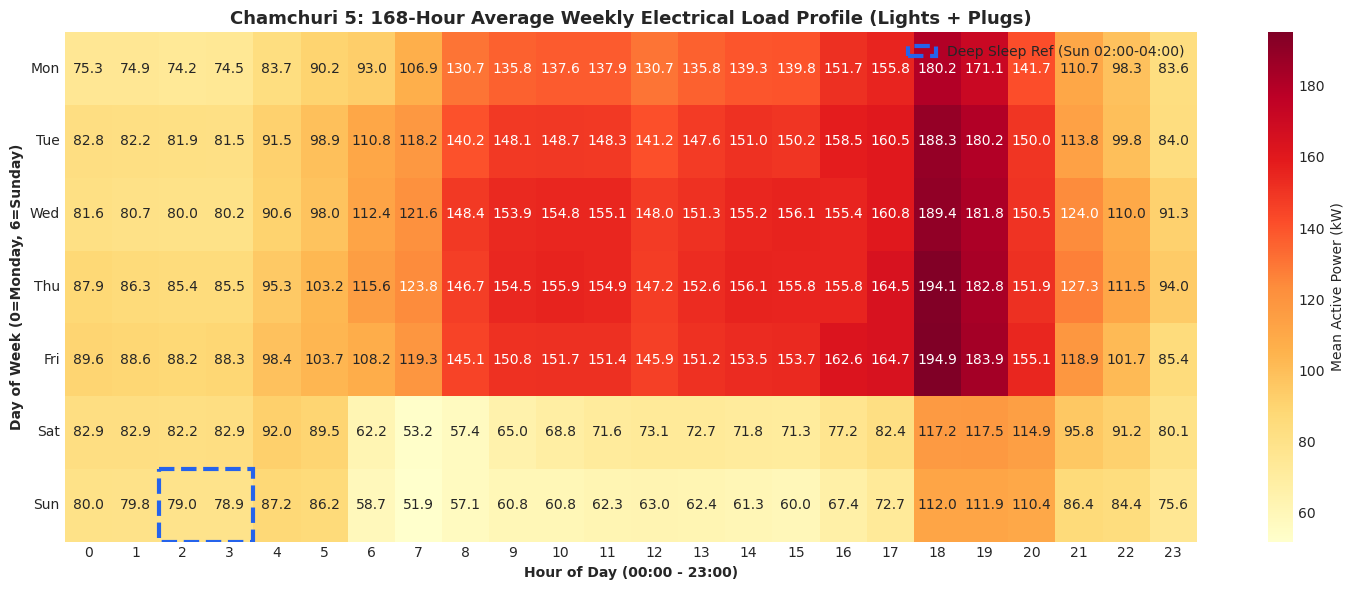

In [3]:
# ==============================================================================
# 3. 168-HOUR BUILDING LOAD HEATMAP
# ==============================================================================
bldg_load = pd.concat([df[[c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]] 
                       for df in floor_dfs.values()], axis=1).sum(axis=1)

weekly_matrix = bldg_load.groupby([bldg_load.index.dayofweek, bldg_load.index.hour]).mean().unstack()

plt.figure(figsize=(15, 6))
sns.heatmap(weekly_matrix, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Mean Active Power (kW)'})
plt.title("Chamchuri 5: 168-Hour Average Weekly Electrical Load Profile (Lights + Plugs)", fontsize=13, fontweight='bold')
plt.xlabel("Hour of Day (00:00 - 23:00)", fontweight='bold')
plt.ylabel("Day of Week (0=Monday, 6=Sunday)", fontweight='bold')
plt.yticks(ticks=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5], labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], rotation=0)

# Highlight deep sleep reference window: Sunday (day 6), hours 2 and 3 (02:00-04:00)
from matplotlib.patches import Rectangle
plt.gca().add_patch(Rectangle((2, 6), 2, 1, fill=False, edgecolor='#2563EB', lw=3, ls='--', label='Deep Sleep Ref (Sun 02:00-04:00)'))
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

min_val = weekly_matrix.loc[6, 2:3].mean()


> **Empirical Baseload Calibration Finding**:
> Across the 168-hour weekly operational profile, **Sunday 02:00–04:00 AM** represents the verified **lowest-occupancy, most stable overnight load window (79.0 kW average)** across the 18-month telemetry (80.7 kW in the 12-month training period). This captures steady-state quiescent machine baseload and timer-controlled exterior illumination during the period of lowest human activity.


### Reference window: Sunday 02:00–04:00

Besides the dynamic baseload (Section 5), we keep one **reference value per circuit**: the 2.5th percentile of its load on Sundays 02:00–04:00,
the quietest steady part of the week. It is used only (1) as a fallback when an after-hours `(day, hour)` slot has no training data
(e.g. a weekday-daytime holiday slot that never occurred in the training year) and (2) as the `Baseload_kW` column in the exported table.
Sunday 06:00–08:00 has a lower building total, but only because exterior lights switch off at sunrise, so it is a transition, not a steady state.

## 4. Empirical Schedule Validation: Weekday vs. Saturday Load Profiles
To validate the assumed 08:00–17:00 occupied schedule against physical building behavior, we plot the mean hourly profile of workdays vs. Saturdays.


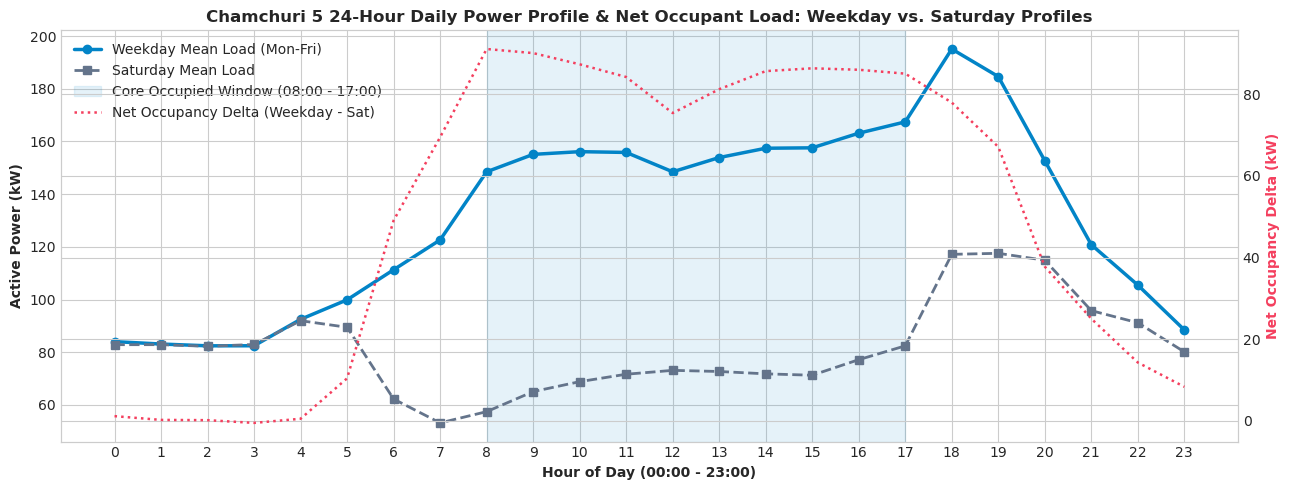

In [4]:
# ==============================================================================
# 4. SCHEDULE VALIDATION: WEEKDAY VS SATURDAY HOURLY PROFILE
# ==============================================================================
wkday_mask = (bldg_load.index.dayofweek < 5) & (~pd.Series(bldg_load.index.date, index=bldg_load.index).isin(holiday_dates))
sat_mask = bldg_load.index.dayofweek == 5

mean_wkday = bldg_load.loc[wkday_mask].groupby(bldg_load.loc[wkday_mask].index.hour).mean()
mean_sat = bldg_load.loc[sat_mask].groupby(bldg_load.loc[sat_mask].index.hour).mean()

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(mean_wkday.index, mean_wkday.values, color='#0284C7', lw=2.5, marker='o', label='Weekday Mean Load (Mon-Fri)')
ax1.plot(mean_sat.index, mean_sat.values, color='#64748B', lw=2.0, ls='--', marker='s', label='Saturday Mean Load')
ax1.axvspan(8, 17, color='#0284C7', alpha=0.10, label='Core Occupied Window (08:00 - 17:00)')

# Net occupancy delta on secondary axis
ax2 = ax1.twinx()
delta = mean_wkday - mean_sat
ax2.plot(delta.index, delta.values, color='#F43F5E', lw=1.8, ls=':', label='Net Occupancy Delta (Weekday - Sat)')
ax2.set_ylabel("Net Occupancy Delta (kW)", color='#F43F5E', fontweight='bold')

ax1.set_xlabel("Hour of Day (00:00 - 23:00)", fontweight='bold')
ax1.set_ylabel("Active Power (kW)", fontweight='bold')
ax1.set_title("Chamchuri 5 24-Hour Daily Power Profile & Net Occupant Load: Weekday vs. Saturday Profiles", fontsize=12, fontweight='bold')
ax1.set_xticks(range(24))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()



> **Operational Schedule Boundary Validation Finding**:
> * **Daytime Surge**: Active power surges by an average of **+85.3 kW** between 08:00 and 17:00 on weekdays relative to Saturday.
> * **Evening Decline**: Load declines steadily after 17:00 (dropping to 105.5 kW at 22:00 and 88.5 kW at 23:00, converging on the ~79–80 kW overnight floor after midnight).
> * **Conclusion**: Mon–Fri 08:00–17:00 is stable across years as the occupied boundary; after 17:00 represents unoccupied curfew hours.


## 5. Mathematical Baseload Derivation: Dynamic Time-of-Week ($P_{2.5}$)

We derive the circuit baseload using the **2.5th percentile ($P_{2.5}, q=0.025$)**:
1. **Reference Quiescent Baseload ($B_{i,\text{ref}}$)**: Evaluated during the deep-sleep calibration window (Sundays 02:00–04:00 AM) across 52 training weeks. Used as the core feature for machine learning circuit clustering.
2. **Dynamic Time-of-Week Operational Baseload ($B_i(d, h)$)**: Evaluated for each of the unoccupied time-of-week slots across the training year. This accommodates natural operational departure transitions (e.g. 17:00–19:00 evening shoulder) while maintaining the deep-night floor during quiescent hours.


In [5]:
# ==============================================================================
# 5. BASELOAD DERIVATION ACROSS ALL 65 CIRCUITS (STATIC + DYNAMIC TIME-OF-WEEK P2.5)
# ==============================================================================
BASELOAD_PERCENTILE = 0.025
REF_DAY_OF_WEEK     = 6        # Sunday
REF_HOUR_START      = 2        # 02:00 AM
REF_HOUR_END        = 4        # 04:00 AM (exclusive: 02:00 to 04:00 AM)
pct_label = f"P{BASELOAD_PERCENTILE * 100:g}"

sunday_baseloads = {}
baseload_records = []

# 1. Calibrate Reference Deep-Sleep Window (Sundays 02:00-04:00) for Clustering
for floor_name, df in floor_dfs.items():
    train_df = df[df['Split'] == 'Train']
    ref_window = train_df[(train_df['DayOfWeek'] == REF_DAY_OF_WEEK) & 
                          (train_df['Hour'] >= REF_HOUR_START) & 
                          (train_df['Hour'] < REF_HOUR_END)]
    
    p_cols = [c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
    
    for col in p_cols:
        c_type = 'Lighting' if '_Light' in col else 'Plug Load'
        series = ref_window[col].dropna()
        b_val = float(series.quantile(BASELOAD_PERCENTILE)) if len(series) > 0 else 0.0
        if np.isnan(b_val): b_val = 0.0
        
        cv = float(series.std() / (series.mean() + 1e-4)) if len(series) > 0 else 0.0
        circuit_id = f"{floor_name}_{col}"
        sunday_baseloads[circuit_id] = b_val
        
        baseload_records.append({
            'Circuit_ID': circuit_id,
            'Floor': floor_name,
            'Type': c_type,
            f'Baseload_kW_{pct_label}': round(b_val, 2),
            'Ref_Mean_kW': round(float(series.mean()), 2) if len(series) > 0 else 0.0,
            'CV': round(cv, 3),
        })

baseload_df = pd.DataFrame(baseload_records)

# 2. Calibrate Dynamic Time-of-Week Baseload Matrix: B_i(DayOfWeek, Hour)
# Load hourly master dataset to compute unoccupied time-of-week quantiles
master_hourly = pd.read_csv(os.path.join(data_dir, 'qn1_hourly_master_for_excel.csv'), parse_dates=['Date'], index_col='Date')
train_unocc_h = master_hourly[(master_hourly['Is_Train_Period'] == 1) & (master_hourly['Is_Unoccupied'] == 1)]

all_circuit_cols = [c for c in master_hourly.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
dynamic_base_matrix = train_unocc_h.groupby([train_unocc_h.index.dayofweek, train_unocc_h.index.hour])[all_circuit_cols].quantile(BASELOAD_PERCENTILE)
dynamic_base_matrix.index.names = ['DayOfWeek', 'Hour']

# Export dynamic baseload matrix for digital twin synchronization
dyn_matrix_export_path = os.path.join(data_dir, 'qn1_dynamic_baseload_matrix.csv')
dynamic_base_matrix.reset_index().to_csv(dyn_matrix_export_path, index=False)
print(f"[OK] Dynamic Baseload Matrix calibrated across 168h and exported -> {os.path.basename(dyn_matrix_export_path)}")

display(baseload_df[['Circuit_ID', 'Floor', 'Type', f'Baseload_kW_{pct_label}', 'Ref_Mean_kW', 'CV']].head(10))


[OK] Dynamic Baseload Matrix calibrated across 168h and exported -> qn1_dynamic_baseload_matrix.csv


,Circuit_ID,Floor,Type,Baseload_kW_P2.5,Ref_Mean_kW,CV
0,Floor1_z1_Light(kW),Floor1,Lighting,0.00,11.03,0.602
1,Floor1_z1_Plug(kW),Floor1,Plug Load,0.04,4.38,1.499
2,Floor1_z2_Light(kW),Floor1,Lighting,4.23,11.24,0.397
3,Floor1_z2_Plug(kW),Floor1,Plug Load,8.39,15.45,0.190
4,Floor1_z3_Light(kW),Floor1,Lighting,5.52,12.43,0.329
5,Floor1_z3_Plug(kW),Floor1,Plug Load,0.37,1.14,0.505
6,Floor1_z4_Light(kW),Floor1,Lighting,5.19,21.57,0.524
7,Floor2_z1_Light(kW),Floor2,Lighting,0.01,0.03,3.585
8,Floor2_z1_Plug(kW),Floor2,Plug Load,0.09,0.18,0.300
9,Floor2_z2_Light(kW),Floor2,Lighting,0.00,0.00,0.000


> **Mathematical Baseload Derivation Finding ($P_{2.5}$)**:
> * **Deep-Night Calibration ($P_{2.5}$)**: Quiescent floors were calibrated using the 2.5th percentile during the Sunday 02:00–04:00 AM window across 52 training weeks. The electrical engine room (`Floor1_z2_Plug`) has the highest floor, **8.39 kW**, with a Sunday-night CV of **0.190**.
> * **Dynamic Time-of-Week Operational Matrix ($P_{2.5}(d, h)$)**: Calibrated across all unoccupied `(DayOfWeek, Hour)` slots, establishing an achievable baseload that respects normal evening departure transitions while maintaining deep-night quiescent floors.


## 6. Deliverable 02: Circuit Classification (Critical Standby vs. Preventable Waste)

We cluster all 65 circuits with **K-Means** on five **behaviour features**. Each feature describes a circuit **relative to its own load**, so circuits are grouped by *how* they use electricity after hours, not by *how big* they are: a 0.3 kW stair-hall plug circuit and the 19 kW electrical engine room look alike if they both run around the clock. All features use the **training year only** (Jul 2018 – Jun 2019).

| Feature | Question it answers | Critical Standby (24/7) | Preventable (follows occupancy) |
| :--- | :--- | :--- | :--- |
| `Night_On_Frac` | Share of after-hours hours the circuit is clearly ON (> 20 % of its own peak) | ≈ 1.0 | low (≈ 0.1–0.3) |
| `Base_to_Peak` | Overnight floor ($P_{2.5}$ of after-hours load) ÷ its own peak ($P_{95}$) | high: barely drops | ≈ 0: drops to nothing |
| `Night_to_Day` | Mean load 19:00–05:00 ÷ mean occupied-hours load (log) | ≈ 1 | ≪ 1 (night/timer lights: ≫ 1) |
| `Weekend_to_Weekday` | Weekend 09:00–17:00 mean ÷ weekday occupied mean (log) | ≈ 1 | ≪ 1 |
| `OffHours_CV` | Volatility of after-hours load (σ/μ) | low (steady machine) | high (human switching) |

K-Means finds three behaviour groups, which map to the Deliverable 02 labels:

| Behaviour group | Deliverable 02 label | Action |
| :--- | :--- | :--- |
| Critical Standby (24/7 steady) | **Critical Standby** | Keep on; 0 waste counted |
| Extended-Hours / Scheduled | **Preventable Waste** | Timer-like pattern, likely an operating rule not in the data: reschedule, or the facility manager adds an exception in the dashboard |
| Occupancy-Following | **Preventable Waste** | Switch off after hours |

The full justification, with worked examples for every feature, is in [`qn1_kmeans_feature_justification.md`](qn1_kmeans_feature_justification.md).

In [6]:
# ==============================================================================
# 6.1 BEHAVIOUR FEATURES FOR ALL 65 CIRCUITS (TRAINING YEAR ONLY)
# ==============================================================================
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

PEAK_Q       = 0.95      # a circuit's own "typical peak" = 95th percentile of its hourly load
ON_THRESHOLD = 0.20      # "clearly ON" = above 20% of the circuit's own peak
NIGHT_START, NIGHT_END = 19, 5   # night window 19:00-05:00
DAY_START, DAY_END     = 9, 17   # daytime window for the weekend comparison
RATIO_FLOOR  = 0.01      # floor for ratios before taking logs

BEHAVIOUR_FEATURES = ['Night_On_Frac', 'Base_to_Peak', 'Night_to_Day', 'Weekend_to_Weekday', 'OffHours_CV']
LOG_FEATURES = ['Night_to_Day', 'Weekend_to_Weekday']

def behaviour_features(hourly, circuits):
    """One row per circuit; every feature is relative to the circuit's own load level."""
    h, dow = hourly.index.hour, hourly.index.dayofweek
    occ   = (hourly['Is_Occupied'] == 1).to_numpy()
    unocc = (hourly['Is_Unoccupied'] == 1).to_numpy()
    night = (h >= NIGHT_START) | (h < NIGHT_END)
    wkend_day = (dow >= 5) & (h >= DAY_START) & (h < DAY_END)
    rows = []
    for c in circuits:
        s = hourly[c]
        peak = s.quantile(PEAK_Q)
        s_unocc = s[unocc].dropna()
        occ_mean = s[occ].mean()
        rows.append({
            'Circuit_ID': c,
            'Night_On_Frac': float((s_unocc > ON_THRESHOLD * peak).mean()),
            'Base_to_Peak': float(s_unocc.quantile(BASELOAD_PERCENTILE) / peak) if peak > 0 else 0.0,
            'Night_to_Day': float(s[night].mean() / (occ_mean + 1e-3)),
            'Weekend_to_Weekday': float(s[wkend_day].mean() / (occ_mean + 1e-3)),
            'OffHours_CV': float(s_unocc.std() / (s_unocc.mean() + 1e-4)),
            'Peak_kW': float(peak),
        })
    return pd.DataFrame(rows).set_index('Circuit_ID')

def to_model_matrix(feat):
    """Log-transform the two ratio features (they span 0.02 to 30), leave the bounded ones as they are."""
    X = feat[BEHAVIOUR_FEATURES].copy()
    X[LOG_FEATURES] = np.log(X[LOG_FEATURES].clip(lower=RATIO_FLOOR))
    return X

hourly_train = master_hourly[master_hourly['Is_Train_Period'] == 1]
beh_train = behaviour_features(hourly_train, all_circuit_cols)
X_beh_raw = to_model_matrix(beh_train)

# Skewness before vs after the log transform (K-Means uses Euclidean distance, so heavy skew lets a few circuits dominate)
skew_df = pd.DataFrame({'Skew_Raw': beh_train[BEHAVIOUR_FEATURES].skew(),
                        'Skew_Used_In_Model': X_beh_raw.skew()}).round(2)
print('=== FEATURE SKEWNESS (raw vs. as used in K-Means) ===')
display(skew_df)

print('=== SPEARMAN CORRELATION BETWEEN FEATURES (|rho| < 0.9 -> no feature is a duplicate) ===')
display(beh_train[BEHAVIOUR_FEATURES].corr(method='spearman').round(2))

=== FEATURE SKEWNESS (raw vs. as used in K-Means) ===


,Skew_Raw,Skew_Used_In_Model
Night_On_Frac,1.31,1.31
Base_to_Peak,3.27,3.27
Night_to_Day,5.99,1.25
Weekend_to_Weekday,1.35,0.13
OffHours_CV,0.10,0.10


=== SPEARMAN CORRELATION BETWEEN FEATURES (|rho| < 0.9 -> no feature is a duplicate) ===


,Night_On_Frac,Base_to_Peak,Night_to_Day,Weekend_to_Weekday,OffHours_CV
Night_On_Frac,1.00,0.42,0.72,0.87,-0.59
Base_to_Peak,0.42,1.00,0.68,0.39,-0.83
Night_to_Day,0.72,0.68,1.00,0.77,-0.85
Weekend_to_Weekday,0.87,0.39,0.77,1.00,-0.59
OffHours_CV,-0.59,-0.83,-0.85,-0.59,1.00


In [7]:
# ==============================================================================
# 6.2 CHOOSE k, FIT K-MEANS, NAME THE GROUPS, AND ASSIGN DELIVERABLE 02 LABELS
# ==============================================================================
beh_scaler = StandardScaler().fit(X_beh_raw)
X_beh = beh_scaler.transform(X_beh_raw)

k_rows = []
for k in range(2, 7):
    lab = KMeans(n_clusters=k, random_state=42, n_init=50).fit(X_beh).labels_
    k_rows.append({'k': k, 'Silhouette': round(silhouette_score(X_beh, lab), 3),
                   'Cluster_Sizes': sorted(np.bincount(lab).tolist(), reverse=True)})
print('=== CANDIDATE k ===')
display(pd.DataFrame(k_rows))

# k = 3 is the smallest k that separates the three physical behaviours (see markdown below):
# k = 2 has a slightly higher silhouette but merges the 24/7 loads with the timer-like extended-hours circuits.
BEHAVIOUR_K = 3
km_beh = KMeans(n_clusters=BEHAVIOUR_K, random_state=42, n_init=50).fit(X_beh)
beh_train['Cluster'] = km_beh.labels_

# Name clusters from their medians, so names do not depend on K-Means' arbitrary label numbers
GROUP_CRITICAL = 'Critical Standby (24/7 Steady)'
GROUP_EXTENDED = 'Extended-Hours / Scheduled'
GROUP_OCCUPANCY = 'Occupancy-Following'
cl_med = beh_train.groupby('Cluster')[BEHAVIOUR_FEATURES].median()
crit_id = cl_med['Base_to_Peak'].idxmax()
occ_id = cl_med['Night_On_Frac'].idxmin()
ext_ids = [c for c in cl_med.index if c not in (crit_id, occ_id)]
assert crit_id != occ_id and len(ext_ids) == 1, 'Cluster naming is ambiguous; inspect cl_med'
cluster_names = {crit_id: GROUP_CRITICAL, occ_id: GROUP_OCCUPANCY, ext_ids[0]: GROUP_EXTENDED}
beh_train['Behaviour_Group'] = beh_train['Cluster'].map(cluster_names)
group_order = [GROUP_CRITICAL, GROUP_EXTENDED, GROUP_OCCUPANCY]

profile = beh_train.groupby('Behaviour_Group')[BEHAVIOUR_FEATURES].median().reindex(group_order).round(2)
profile['Circuits'] = beh_train['Behaviour_Group'].value_counts().reindex(group_order)
print(f'=== CLUSTER PROFILES (median feature values), k={BEHAVIOUR_K}, silhouette={silhouette_score(X_beh, km_beh.labels_):.3f} ===')
display(profile)

for g in [GROUP_CRITICAL, GROUP_EXTENDED]:
    members = beh_train.index[beh_train['Behaviour_Group'] == g].str.replace('(kW)', '', regex=False)
    print(f'{g} ({len(members)}): {", ".join(members)}')

# Deliverable 02 labels: only the 24/7 group is protected; scheduled and occupancy-following loads are preventable
h_occ = (hourly_train['Is_Occupied'] == 1).to_numpy()
h_unocc = (hourly_train['Is_Unoccupied'] == 1).to_numpy()
feat_df = pd.DataFrame({'Circuit_ID': all_circuit_cols})
feat_df['Floor'] = feat_df['Circuit_ID'].str.split('_').str[0]
feat_df['Zone_Col'] = [c.replace(f"{f}_", "").replace("(kW)", "") for c, f in zip(feat_df['Circuit_ID'], feat_df['Floor'])]
feat_df['Type'] = np.where(feat_df['Circuit_ID'].str.contains('_Light'), 'Lighting', 'Plug Load')
feat_df['Baseload_kW'] = feat_df['Circuit_ID'].map(sunday_baseloads)          # Sunday 02:00-04:00 P2.5 (Section 5)
feat_df['Unocc_to_Occ_Ratio'] = [hourly_train.loc[h_unocc, c].mean() / (hourly_train.loc[h_occ, c].mean() + 1e-3)
                                 for c in all_circuit_cols]                    # descriptive, not a clustering feature
feat_df = feat_df.join(beh_train[BEHAVIOUR_FEATURES + ['Behaviour_Group']], on='Circuit_ID')
feat_df['Classification'] = np.where(feat_df['Behaviour_Group'] == GROUP_CRITICAL, 'Critical Standby', 'Preventable Waste')

print('\n=== DELIVERABLE 02 LABELS ===')
display(pd.crosstab(feat_df['Behaviour_Group'], feat_df['Classification']).reindex(group_order))


=== CANDIDATE k ===


,k,Silhouette,Cluster_Sizes
0,2,0.511,"[49, 16]"
1,3,0.426,"[43, 16, 6]"
2,4,0.351,"[27, 22, 11, 5]"
3,5,0.367,"[27, 22, 8, 4, 4]"
4,6,0.373,"[22, 17, 12, 6, 4, 4]"


=== CLUSTER PROFILES (median feature values), k=3, silhouette=0.426 ===


,Night_On_Frac,Base_to_Peak,Night_to_Day,Weekend_to_Weekday,OffHours_CV,Circuits
Behaviour_Group,,,,,,
Critical Standby (24/7 Steady),1.00,0.58,0.96,0.96,0.16,6
Extended-Hours / Scheduled,0.53,0.04,0.44,0.43,0.74,16
Occupancy-Following,0.21,0.00,0.07,0.15,1.62,43


Critical Standby (24/7 Steady) (6): Floor1_z2_Light, Floor1_z2_Plug, Floor2_z3_Plug, Floor3_z3_Plug, Floor5_z3_Plug, Floor6_z3_Plug
Extended-Hours / Scheduled (16): Floor1_z1_Light, Floor1_z1_Plug, Floor1_z3_Light, Floor1_z3_Plug, Floor1_z4_Light, Floor2_z3_Light, Floor2_z4_Plug, Floor4_z2_Plug, Floor4_z3_Light, Floor4_z3_Plug, Floor4_z5_Plug, Floor6_z1_Plug, Floor6_z3_Light, Floor7_z3_Light, Floor7_z3_Plug, Floor7_z5_Plug

=== DELIVERABLE 02 LABELS ===


Classification,Critical Standby,Preventable Waste
Behaviour_Group,,
Critical Standby (24/7 Steady),6,0
Extended-Hours / Scheduled,0,16
Occupancy-Following,0,43


In [8]:
# ==============================================================================
# 6.3 DOES EVERY FEATURE MATTER? ABLATION + STABILITY CHECKS
# ==============================================================================
def _align(ref, lab):
    """Relabel `lab` so each of its clusters takes the reference label it overlaps most."""
    ct = pd.crosstab(lab, ref)
    return np.array([ct.loc[l].idxmax() for l in lab])

def ablation(X, names, k, full_labels, drop_sets):
    """For each set of features removed: ARI vs the full clustering, and how many circuits change group.
    ARI = 1.0 and 0 moved -> the removed feature(s) contribute nothing."""
    rows = []
    for drop in drop_sets:
        keep = [i for i, n in enumerate(names) if n not in drop]
        lab = KMeans(n_clusters=k, random_state=42, n_init=50).fit(X[:, keep]).labels_
        rows.append({'Feature_Removed': ' + '.join(drop),
                     'ARI_vs_Full': round(adjusted_rand_score(full_labels, lab), 2),
                     'Circuits_Moved': int((_align(full_labels, lab) != full_labels).sum())})
    return pd.DataFrame(rows)

ablation_df = ablation(X_beh, BEHAVIOUR_FEATURES, BEHAVIOUR_K, km_beh.labels_,
                       [[n] for n in BEHAVIOUR_FEATURES] + [['Weekend_to_Weekday', 'OffHours_CV']])
ablation_df['Contribution'] = np.select(
    [ablation_df['Circuits_Moved'] == 0, ablation_df['ARI_vs_Full'] >= 0.9],
    ['None (redundant)', 'Weak (tie-breaker)'], 'Strong')
ablation_df = ablation_df[['Feature_Removed', 'ARI_vs_Full', 'Circuits_Moved', 'Contribution']]
print('=== ABLATION: ARI between full clustering and clustering without each feature ===')
display(ablation_df)

# Seed stability: K-Means starts from random centroids; the grouping should not depend on the seed
seed_ari = [adjusted_rand_score(km_beh.labels_, KMeans(n_clusters=BEHAVIOUR_K, random_state=s, n_init=50).fit(X_beh).labels_)
            for s in range(10)]
from sklearn.metrics import silhouette_samples
beh_train['Silhouette'] = silhouette_samples(X_beh, km_beh.labels_)
print('=== SILHOUETTE BY GROUP (higher = more clearly in its own group) ===')
display(beh_train.groupby('Behaviour_Group')['Silhouette'].agg(['mean', 'min', 'count']).reindex(group_order).round(2))
borderline = beh_train.loc[beh_train['Silhouette'] < 0.10, ['Behaviour_Group', 'Silhouette']].sort_values('Silhouette').round(2)
print(f'Borderline circuits (silhouette < 0.10): {len(borderline)}')
display(borderline)

print(f'Seed stability: minimum ARI across 10 random seeds = {min(seed_ari):.3f}')

# Out-of-sample stability: recompute features on Jul-Dec 2019 and assign each circuit to the TRAINED centroids
hourly_test = master_hourly[master_hourly.index >= '2019-07-01']
beh_test = behaviour_features(hourly_test, all_circuit_cols)
test_groups = pd.Series(km_beh.predict(beh_scaler.transform(to_model_matrix(beh_test))), index=beh_test.index).map(cluster_names)
same = (test_groups == beh_train['Behaviour_Group'])
print(f'Out-of-sample stability: {same.mean():.1%} of circuits keep the same group on Jul-Dec 2019 data')
moved = pd.DataFrame({'Train_Group': beh_train.loc[~same, 'Behaviour_Group'], 'Test_Group': test_groups[~same]})
if len(moved):
    display(moved)

=== ABLATION: ARI between full clustering and clustering without each feature ===


,Feature_Removed,ARI_vs_Full,Circuits_Moved,Contribution
0,Night_On_Frac,0.54,10,Strong
1,Base_to_Peak,0.34,16,Strong
2,Night_to_Day,0.29,16,Strong
3,Weekend_to_Weekday,0.98,1,Weak (tie-breaker)
4,OffHours_CV,0.98,1,Weak (tie-breaker)
5,Weekend_to_Weekday + OffHours_CV,0.87,3,Strong


=== SILHOUETTE BY GROUP (higher = more clearly in its own group) ===


,mean,min,count
Behaviour_Group,,,
Critical Standby (24/7 Steady),0.49,0.06,6
Extended-Hours / Scheduled,0.27,0.07,16
Occupancy-Following,0.47,0.07,43


Borderline circuits (silhouette < 0.10): 4


,Behaviour_Group,Silhouette
Circuit_ID,,
Floor1_z2_Light(kW),Critical Standby (24/7 Steady),0.06
Floor4_z3_Plug(kW),Extended-Hours / Scheduled,0.07
Floor4_z3_Light(kW),Extended-Hours / Scheduled,0.07
Floor7_z1_Plug(kW),Occupancy-Following,0.07


Seed stability: minimum ARI across 10 random seeds = 0.944
Out-of-sample stability: 89.2% of circuits keep the same group on Jul-Dec 2019 data


,Train_Group,Test_Group
Circuit_ID,,
Floor3_z3_Light(kW),Occupancy-Following,Extended-Hours / Scheduled
Floor4_z3_Plug(kW),Extended-Hours / Scheduled,Critical Standby (24/7 Steady)
Floor4_z4_Light(kW),Occupancy-Following,Extended-Hours / Scheduled
Floor5_z4_Plug(kW),Occupancy-Following,Extended-Hours / Scheduled
Floor6_z5_Plug(kW),Occupancy-Following,Extended-Hours / Scheduled
Floor7_z1_Plug(kW),Occupancy-Following,Extended-Hours / Scheduled
Floor7_z3_Plug(kW),Extended-Hours / Scheduled,Critical Standby (24/7 Steady)


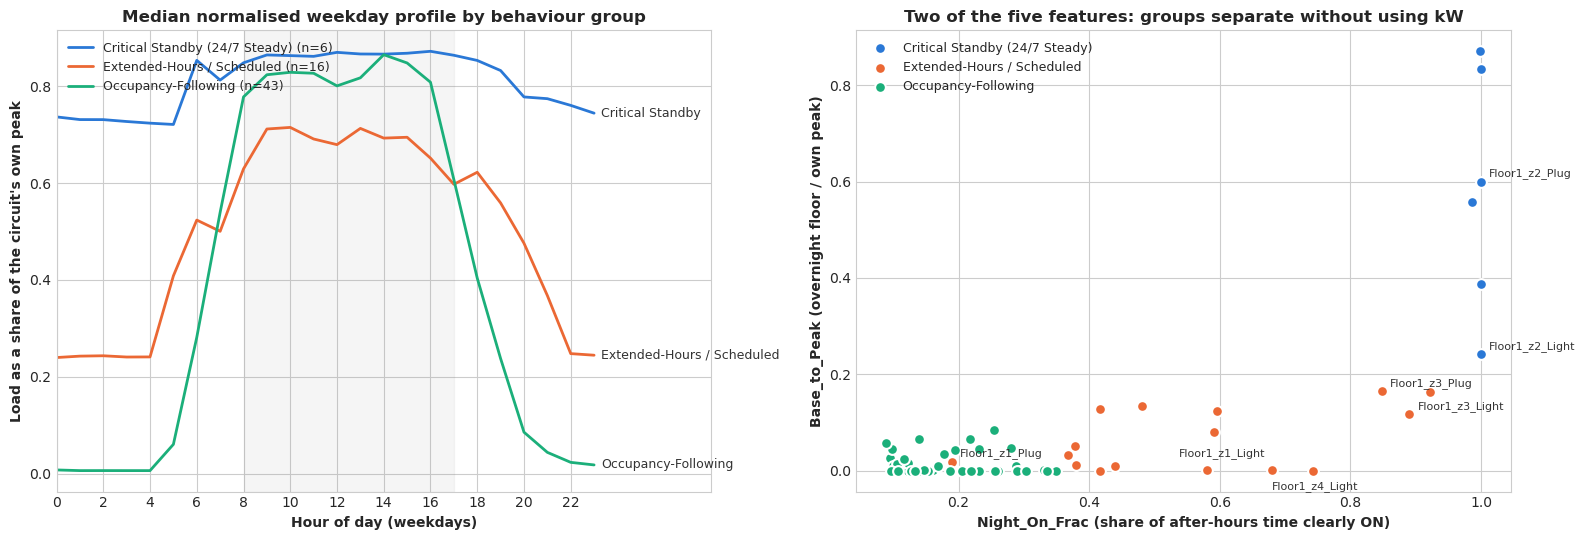

In [9]:
# ==============================================================================
# 6.4 DO THE GROUPS BEHAVE DIFFERENTLY? NORMALISED 24-HOUR PROFILES + FEATURE MAP
# ==============================================================================
GROUP_COLORS = {GROUP_CRITICAL: '#2a78d6', GROUP_EXTENDED: '#eb6834', GROUP_OCCUPANCY: '#1baf7a'}

# Each circuit's mean load by hour of day (weekdays, training year), divided by its own P95 peak
wk = hourly_train[hourly_train.index.dayofweek < 5]
norm_profiles = wk[all_circuit_cols].groupby(wk.index.hour).mean() / beh_train['Peak_kW'].replace(0, np.nan)

fig, (ax_p, ax_s) = plt.subplots(1, 2, figsize=(16, 5.5))
for g in group_order:
    members = beh_train.index[beh_train['Behaviour_Group'] == g]
    med = norm_profiles[members].median(axis=1)
    ax_p.plot(med.index, med.values, color=GROUP_COLORS[g], lw=2, label=f'{g} (n={len(members)})')
    ax_p.text(23.3, med.values[-1], g.split(' (')[0], color='#333333', fontsize=9, va='center')
ax_p.axvspan(8, 17, color='#888888', alpha=0.08)
ax_p.set_xticks(range(0, 24, 2)); ax_p.set_xlim(0, 28)
ax_p.set_xlabel('Hour of day (weekdays)', fontweight='bold')
ax_p.set_ylabel('Load as a share of the circuit\'s own peak', fontweight='bold')
ax_p.set_title('Median normalised weekday profile by behaviour group', fontweight='bold')
ax_p.legend(loc='upper left', fontsize=9)

for g in group_order:
    sub = beh_train[beh_train['Behaviour_Group'] == g]
    ax_s.scatter(sub['Night_On_Frac'], sub['Base_to_Peak'], s=60, color=GROUP_COLORS[g],
                 edgecolors='white', linewidth=1.5, label=g)
label_offsets = {'Floor1_z1_Light(kW)': (-20, 10), 'Floor1_z4_Light(kW)': (0, -14)}
for cid, row in beh_train[beh_train.index.str.startswith('Floor1_')].iterrows():
    if row['Behaviour_Group'] != GROUP_OCCUPANCY:
        ax_s.annotate(cid.replace('(kW)', ''), (row['Night_On_Frac'], row['Base_to_Peak']),
                      textcoords='offset points', xytext=label_offsets.get(cid, (6, 4)), fontsize=8, color='#333333')
ax_s.set_xlabel('Night_On_Frac (share of after-hours time clearly ON)', fontweight='bold')
ax_s.set_ylabel('Base_to_Peak (overnight floor / own peak)', fontweight='bold')
ax_s.set_title('Two of the five features: groups separate without using kW', fontweight='bold')
ax_s.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

> **Deliverable 02: Circuit Classification Findings (training year, k = 3)**:
> * **Three behaviour groups** (silhouette 0.43):
>   * **Critical Standby (24/7 steady, 6 circuits) → Critical Standby**: the Floor 1 Zone 2 electrical engine room (plugs and lighting) and the Zone 3 central stair-hall plug circuits on Floors 2, 3, 5 and 6, which never switch off (on 100 % of after-hours time, keeping 58 % of their peak at their quietest). What the stair-hall plugs supply is not documented; confirm with facilities.
>   * **Extended-Hours / Scheduled (16 circuits) → Preventable Waste**: includes `Floor1_z4_Light` (around the building, i.e. exterior lighting) and `Floor1_z1_Light` (sitting hall), with night-to-day ratios of about 32 and 19, and `Floor1_z3_Light` (central stair hall). They are on about 53 % of after-hours time in a steady, timer-like pattern, which suggests an operating rule (e.g. security or exterior lighting hours) that the data does not record. Because they still drop to ~0 kW, they are labelled Preventable Waste, and the facility manager can keep any of them on, or give them their own hours, through exceptions in the dashboard.
>   * **Occupancy-Following (43 circuits) → Preventable Waste**: upper-floor office lighting and desk plugs, on only 21 % of after-hours time and dropping to ~0 % of peak at night.
> * **Why k = 3:** the silhouette scores for k = 2 (0.51) and k = 3 (0.43) are close and both far from 1, so silhouette alone cannot decide. k = 2 puts the engine room in the same group as the timer-like exterior lighting (4 of its 16 'critical' circuits drop to ~0 kW after hours); k = 3 is the smallest k that separates the three after-hours behaviours: 24/7 steady (on 100 %), timer-like (~53 %) and random on/off (~21 %), with no Critical Standby circuit ever switching off.
> * **Every feature contributes:** removing `Night_On_Frac`, `Base_to_Peak` or `Night_to_Day` moves 10–16 circuits (ARI 0.29–0.54); `Weekend_to_Weekday` and `OffHours_CV` are tie-breakers (1 circuit each, 3 together).
> * **Group quality:** mean silhouette 0.49 (Critical Standby), 0.27 (Extended-Hours) and 0.47 (Occupancy-Following); no circuit has a negative silhouette. Four circuits are borderline (silhouette < 0.10): `Floor1_z2_Light`, `Floor4_z3_Plug`, `Floor4_z3_Light`, `Floor7_z1_Plug`.
> * **Stability:** minimum ARI across 10 random seeds is 0.94, and 89 % of circuits keep the same group when the features are recomputed on unseen Jul–Dec 2019 data; the 7 that move shift only to a neighbouring group.

### Standby Time-Series Verification: Engine Room vs. Office Lighting
We verify that `Floor1_z2_Plug` (Floor 1 Zone 2, the electrical engine room, *Salama 2021 Table 1*) draws continuously, 24/7 (8.39 kW Sunday-night baseload, after-hours CV 0.14), and is classified by K-Means as Critical Standby.

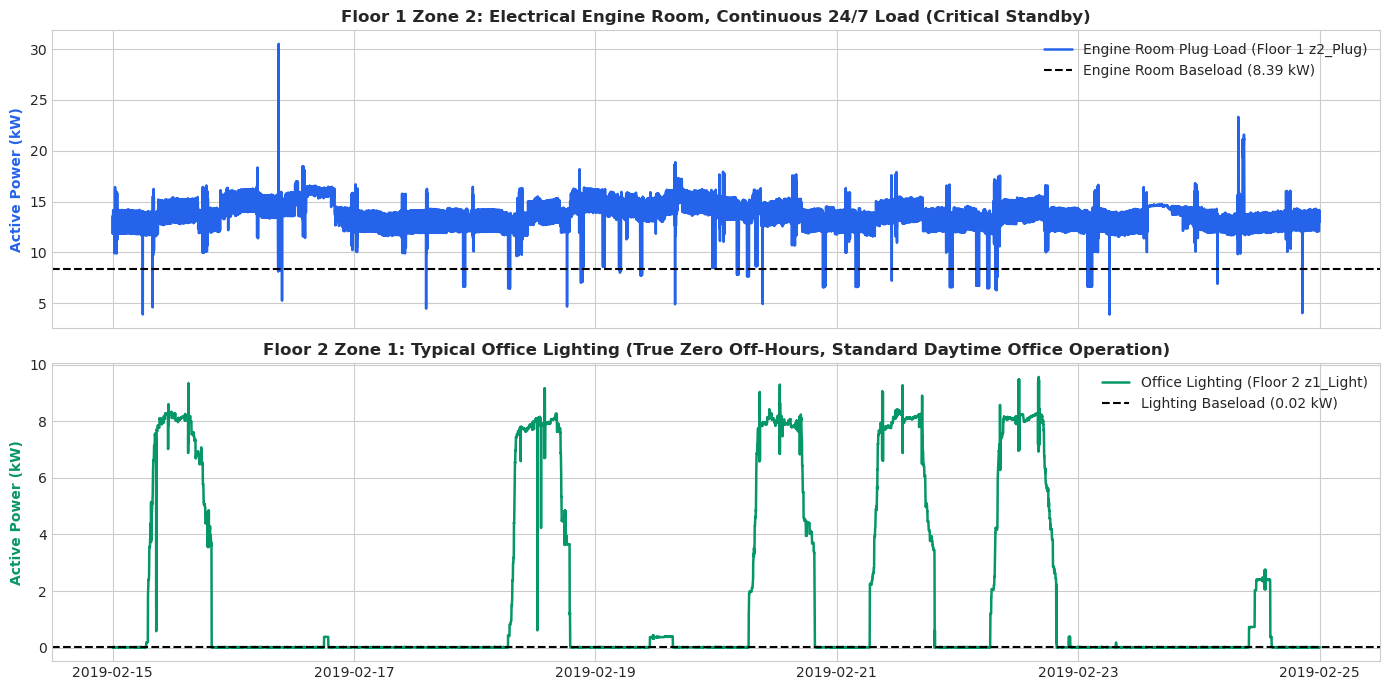

In [10]:
# ==============================================================================
# 6.5 VISUALIZE ENGINE ROOM STANDBY VS OFFICE LIGHTING
# ==============================================================================
f1_df = floor_dfs['Floor1']
f2_df = floor_dfs['Floor2']
sample_range_f1 = f1_df.loc['2019-02-15 00:00:00':'2019-02-25 00:00:00']
sample_range_f2 = f2_df.loc['2019-02-15 00:00:00':'2019-02-25 00:00:00']

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Subplot 1: Engine Room Plug (Floor 1 Zone 2)
axes[0].plot(sample_range_f1.index, sample_range_f1['z2_Plug(kW)'], color='#2563EB', lw=1.8, label='Engine Room Plug Load (Floor 1 z2_Plug)')
axes[0].axhline(sunday_baseloads['Floor1_z2_Plug(kW)'], color='black', ls='--', lw=1.5, label=f'Engine Room Baseload ({sunday_baseloads["Floor1_z2_Plug(kW)"]:.2f} kW)')
axes[0].set_ylabel('Active Power (kW)', color='#2563EB', fontweight='bold')
axes[0].set_title('Floor 1 Zone 2: Electrical Engine Room, Continuous 24/7 Load (Critical Standby)', fontweight='bold')
axes[0].legend(loc='upper right')

# Subplot 2: Typical Upper-Floor Office Lighting (Floor 2 Zone 1)
axes[1].plot(sample_range_f2.index, sample_range_f2['z1_Light(kW)'], color='#059669', lw=1.8, label='Office Lighting (Floor 2 z1_Light)')
axes[1].axhline(sunday_baseloads.get('Floor2_z1_Light(kW)', 0.0), color='black', ls='--', lw=1.5, label='Lighting Baseload (0.02 kW)')
axes[1].set_ylabel('Active Power (kW)', color='#059669', fontweight='bold')
axes[1].set_title('Floor 2 Zone 1: Typical Office Lighting (True Zero Off-Hours, Standard Daytime Office Operation)', fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


## 7. Dynamic Addressable Schedule Surplus Integration

For all circuits classified as **Preventable Waste**, active power during unoccupied hours exceeding the dynamic Time-of-Week baseload is integrated:
$$W_i(t) = \max\Big(0,\, P_i(t) - B_i(d(t), h(t))\Big) \quad \text{for } i \in \text{Preventable Waste}$$

Circuits classified as **Critical Standby** (6 circuits: the electrical engine room's plugs and lighting, and the always-on stair-hall plugs on Floors 2, 3, 5 and 6) are protected essential loads and allocated **zero preventable waste** ($W_i = 0$).


In [11]:
# ==============================================================================
# 7. INTEGRATE ADDRESSABLE SURPLUS ACROSS ALL CIRCUITS (DYNAMIC TIME-OF-WEEK P2.5)
# ==============================================================================
# Dynamically query all Critical Standby circuits from Step 6 (Deliverable 02)
critical_standby_circuits = set(feat_df.loc[feat_df['Classification'] == 'Critical Standby', 'Circuit_ID'])

circuit_waste_records = []
floor_waste_totals = {f'Floor{i}': 0.0 for i in range(1, 8)}
type_waste_totals = {'Lighting': 0.0, 'Plug Load': 0.0}

# 18-Month Unoccupied Telemetry
unocc_master = master_hourly[master_hourly['Is_Unoccupied'] == 1].copy()
unocc_dow = unocc_master.index.dayofweek
unocc_hr = unocc_master.index.hour

circuit_excess_18m = {}
train_unocc_mask = (unocc_master['Is_Train_Period'] == 1).to_numpy()   # training year Jul 2018 - Jun 2019
floor_annual_totals = {f'Floor{i}': 0.0 for i in range(1, 8)}

for col in all_circuit_cols:
    circuit_id = col
    floor_name = col.split('_')[0]
    zone_col = col.replace(f"{floor_name}_", "").replace("(kW)", "")
    c_type = 'Lighting' if '_Light' in col else 'Plug Load'
    ref_b = sunday_baseloads.get(circuit_id, 0.0)
    
    if circuit_id in critical_standby_circuits:
        excess_series = pd.Series(0.0, index=unocc_master.index)
        wasted_18m_kwh = 0.0
    else:
        # Vectorized lookup of dynamic baseload B_i(dow, hour)
        slot_keys = list(zip(unocc_dow, unocc_hr))
        base_series = pd.Series([dynamic_base_matrix.loc[k, col] if k in dynamic_base_matrix.index else ref_b 
                                 for k in slot_keys], index=unocc_master.index)
        excess_series = (unocc_master[col] - base_series).clip(lower=0.0)
        wasted_18m_kwh = float(excess_series.sum()) # hourly kW sum = kWh
        
    circuit_excess_18m[circuit_id] = excess_series
    # Annual figure = actual surplus in the 12-month training year (same basis as the Section 10 headline)
    annual_kwh = float(excess_series[train_unocc_mask].sum())
    
    circuit_waste_records.append({
        'Circuit_ID': circuit_id,
        'Floor': floor_name,
        'Zone_Col': zone_col,
        'Type': c_type,
        'Baseload_kW': round(ref_b, 2),
        'Dynamic_Baseload_Mean_kW': round(float(dynamic_base_matrix[col].mean()), 3),
        'Unocc_Mean_kW': round(float(unocc_master[col].mean()), 2),
        'Surplus_kWh_18M': round(wasted_18m_kwh, 1),
        'Annual_Surplus_kWh': round(annual_kwh, 1)
    })
    
    floor_waste_totals[floor_name] += wasted_18m_kwh
    floor_annual_totals[floor_name] += annual_kwh
    type_waste_totals[c_type] += wasted_18m_kwh

surplus_summary_df = pd.DataFrame(circuit_waste_records)
total_18m_kwh = surplus_summary_df['Surplus_kWh_18M'].sum()
annual_waste_12m_clean = sum(floor_annual_totals.values())

floor_waste_df = pd.DataFrame([{
    'Floor': k,
    'Preventable_Waste_MWh': round(v / 1000.0, 2),
    'Annual_Waste_MWh': round(floor_annual_totals[k] / 1000.0, 2)
} for k, v in floor_waste_totals.items()])


print(f"=== DELIVERABLE 01: DYNAMIC PREVENTABLE SURPLUS SUMMARY ===")
print(f"  18-Month Total Preventable Surplus: {total_18m_kwh:,.1f} kWh ({total_18m_kwh/1000:,.1f} MWh)")
print(f"  Annual Surplus (training year)    : {annual_waste_12m_clean:,.1f} kWh / year ({annual_waste_12m_clean/1000:,.1f} MWh/yr)")
display(floor_waste_df)


=== DELIVERABLE 01: DYNAMIC PREVENTABLE SURPLUS SUMMARY ===
  18-Month Total Preventable Surplus: 532,993.5 kWh (533.0 MWh)
  Annual Surplus (training year)    : 354,264.4 kWh / year (354.3 MWh/yr)


,Floor,Preventable_Waste_MWh,Annual_Waste_MWh
0,Floor1,375.98,252.55
1,Floor2,17.27,10.54
2,Floor3,23.75,14.44
3,Floor4,26.21,16.58
4,Floor5,28.13,18.11
5,Floor6,29.71,21.99
6,Floor7,31.95,20.06


> **Dynamic Addressable Surplus Integration Finding**:
> * **18-Month Cumulative Waste**: **532,994 kWh (533.0 MWh)** across the 59 Preventable Waste circuits under the dynamic Time-of-Week baseload.
> * **Annual Waste (training year, Jul 2018 – Jun 2019)**: **354,264 kWh / year** (the 6 Critical Standby circuits are allocated 0 waste). This is the same basis as the Section 10 headline.
> * **Floor 1 dominates** (252.5 MWh/yr), driven by the exterior, stair-hall and sitting-hall lighting. This is a *theoretical maximum* (everything above the lowest observed level); realistic savings depend on the schedule chosen for these circuits, which the webapp's curfew plan lets facility managers test.

## 8. Forensic Circuit Audit: The 17:00–22:00 Evening Window
We investigate which circuits drive the 17:00–22:00 weekday load to verify whether the evening surge represents people working late or automated architectural facade floodlights.


In [12]:
# ==============================================================================
# 8. EVENING CIRCUIT BREAKDOWN (17:00 - 22:00 WEEKDAYS)
# ==============================================================================
bldg_hourly = master_hourly   # loaded in Section 5
elec_cols = [c for c in bldg_hourly.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]

eve_mask = (bldg_hourly.index.dayofweek < 5) & (bldg_hourly['Is_Occupied'] == 0) & (bldg_hourly.index.hour >= 17) & (bldg_hourly.index.hour < 22)
eve_means = bldg_hourly.loc[eve_mask, elec_cols].mean()

f1_light_tot = eve_means[[c for c in elec_cols if 'Floor1' in c and '_Light' in c]].sum()
f1_plug_tot  = eve_means[[c for c in elec_cols if 'Floor1' in c and '_Plug' in c and 'z2' not in c]].sum()
engine_room_tot   = eve_means['Floor1_z2_Plug(kW)']
up_light_tot = eve_means[[c for c in elec_cols if 'Floor1' not in c and '_Light' in c]].sum()
up_plug_tot  = eve_means[[c for c in elec_cols if 'Floor1' not in c and '_Plug' in c]].sum()
tot_eve      = f1_light_tot + f1_plug_tot + engine_room_tot + up_light_tot + up_plug_tot

eve_breakdown_df = pd.DataFrame([
    {'End_Use_Category': 'Floor 1 Lighting (Facade & Atrium)', 'Mean_Power_kW': round(f1_light_tot, 2), 'Share_of_Evening_Load_%': round(f1_light_tot/tot_eve*100, 1)},
    {'End_Use_Category': 'Floor 1 Zone 2 Electrical Engine Room', 'Mean_Power_kW': round(engine_room_tot, 2), 'Share_of_Evening_Load_%': round(engine_room_tot/tot_eve*100, 1)},
    {'End_Use_Category': 'Upper Floors (2–7) Office Lighting', 'Mean_Power_kW': round(up_light_tot, 2), 'Share_of_Evening_Load_%': round(up_light_tot/tot_eve*100, 1)},
    {'End_Use_Category': 'Upper Floors (2–7) Office Plugs (Desktops)', 'Mean_Power_kW': round(up_plug_tot, 2), 'Share_of_Evening_Load_%': round(up_plug_tot/tot_eve*100, 1)},
    {'End_Use_Category': 'Floor 1 Office Plugs', 'Mean_Power_kW': round(f1_plug_tot, 2), 'Share_of_Evening_Load_%': round(f1_plug_tot/tot_eve*100, 1)},
    {'End_Use_Category': 'Total Evening Active Power (17:00–22:00)', 'Mean_Power_kW': round(tot_eve, 2), 'Share_of_Evening_Load_%': 100.0}
])
display(eve_breakdown_df)


,End_Use_Category,Mean_Power_kW,Share_of_Evening_Load_%
0,Floor 1 Lighting (Facade & Atrium),94.15,57.7
1,Floor 1 Zone 2 Electrical Engine Room,15.39,9.4
2,Upper Floors (2–7) Office Lighting,41.93,25.7
3,Upper Floors (2–7) Office Plugs (Desktops),7.28,4.5
4,Floor 1 Office Plugs,4.37,2.7
5,Total Evening Active Power (17:00–22:00),163.12,100.0


> **Forensic Evening Audit Findings (17:00–22:00 Weekdays)**:
> * **Upper Floor Desktops Collapse**: Office plug receptacles across Floors 2 to 7 combined draw only **7.28 kW** (4.5% of load), indicating that computers are largely powered down and occupants have departed.
> * **Floor 1 Lighting Dominates**: Ground-floor facade and atrium lighting accounts for **57.7% (94.2 kW)** of the entire building's evening power draw.
> * **Upper-Floor Lighting Left On**: Office lighting on Floors 2 to 7 is the second-largest contributor at **25.7% (41.9 kW)** — this is the curfew-actionable component.
> * **Diagnosis**: The evening load peak is driven primarily by dusk architectural floodlights and upper-floor lights left on, not human overtime work (desktop plug loads have already collapsed).


## 9. Deliverable 01: The Waste Map (Per-Circuit, Per-Floor Spatial Analysis)

---

### Deliverable Alignment
> **01 Waste Map**: *A per-circuit, per-floor view of where after-hours baseload runs and how large it is.*

We visualize the spatial distribution of after-hours energy waste through a comprehensive **Heatmap Grid** (Floors 1 to 7 on the Y-axis vs. Zones/Circuits on the X-axis) alongside floor aggregate and end-use breakdowns.


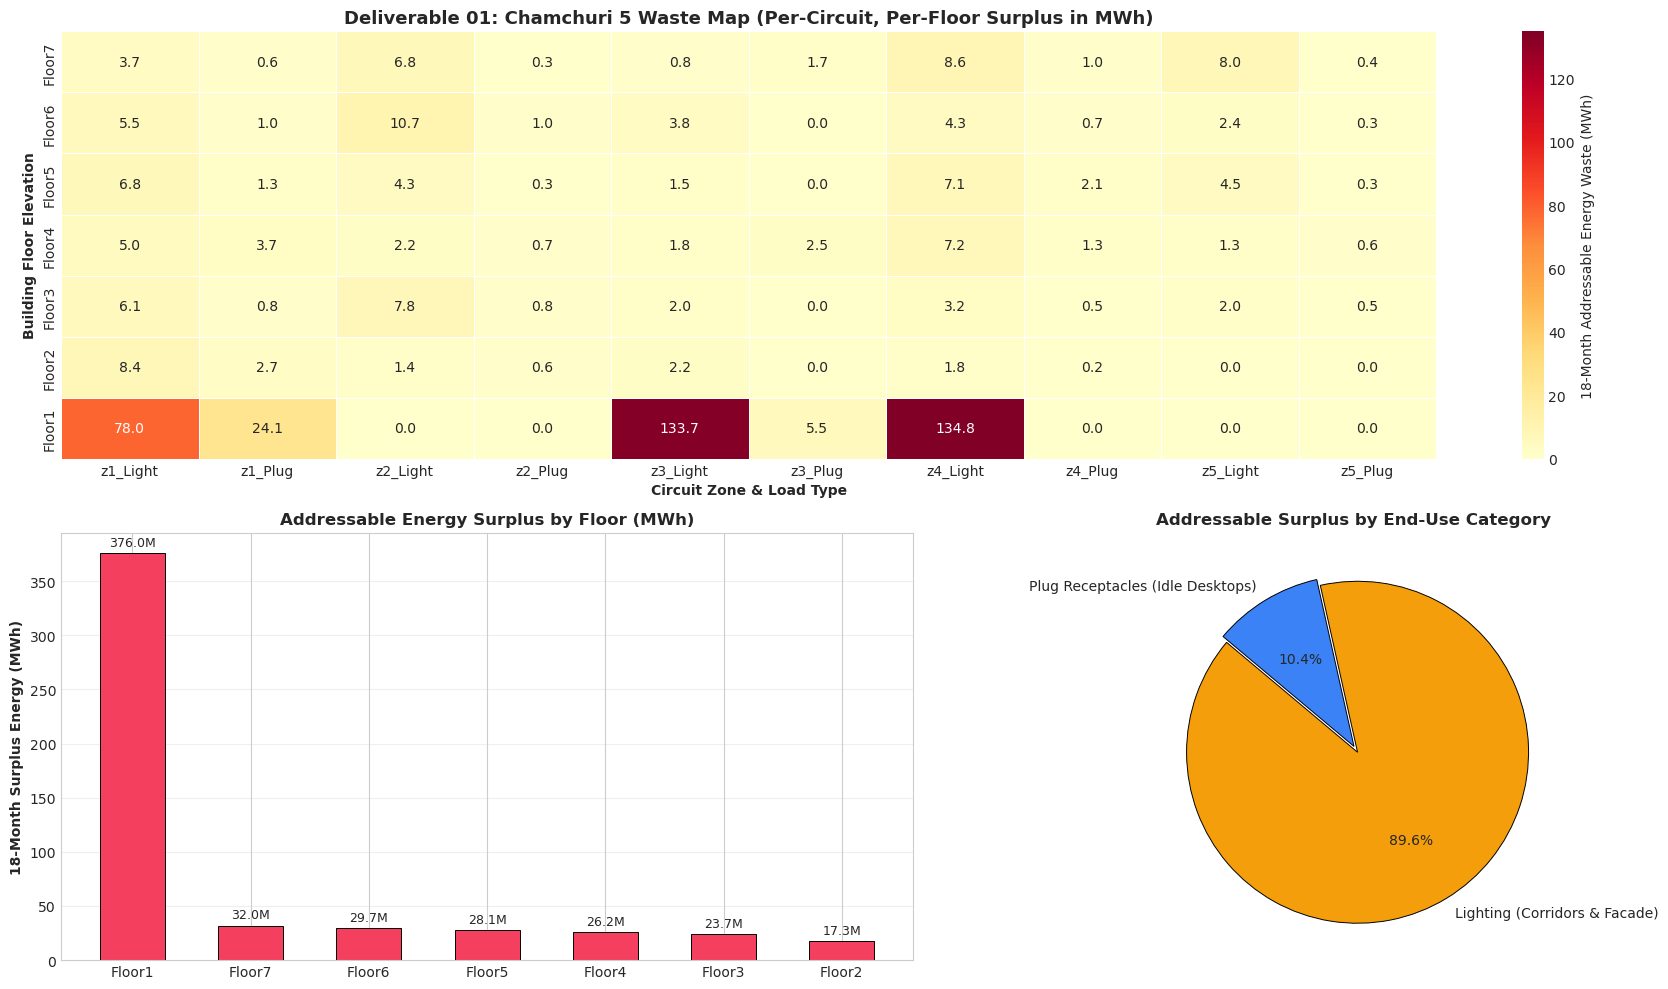

In [13]:
# ==============================================================================
# 9. DELIVERABLE 01: SPATIAL WASTE MAP & BREAKDOWN PLOTS
# ==============================================================================
# 1. Create Per-Circuit, Per-Floor Waste Map Matrix (MWh)
waste_pivot = surplus_summary_df.pivot(index='Floor', columns='Zone_Col', values='Surplus_kWh_18M').fillna(0.0) / 1000.0
# Order floors from Floor 7 down to Floor 1 for architectural elevation perspective
floor_order = [f'Floor{i}' for i in range(7, 0, -1)]
waste_pivot = waste_pivot.reindex(floor_order)

# Reorder columns logically: z1_Light, z1_Plug, z2_Light, z2_Plug, etc.
sorted_cols = sorted(waste_pivot.columns, key=lambda x: (x.split('_')[0], 0 if 'Light' in x else 1))
waste_pivot = waste_pivot[sorted_cols]

# Plot Deliverable 01: Waste Map + Floor Totals + Category Breakdown
fig = plt.figure(figsize=(18, 10))

# Heatmap Matrix (Deliverable 01: Waste Map)
ax_map = plt.subplot2grid((2, 2), (0, 0), colspan=2)
sns.heatmap(waste_pivot, cmap='YlOrRd', annot=True, fmt='.1f', lw=0.5,
            cbar_kws={'label': '18-Month Addressable Energy Waste (MWh)'}, ax=ax_map)
ax_map.set_title("Deliverable 01: Chamchuri 5 Waste Map (Per-Circuit, Per-Floor Surplus in MWh)", fontsize=13, fontweight='bold')
ax_map.set_xlabel("Circuit Zone & Load Type", fontweight='bold')
ax_map.set_ylabel("Building Floor Elevation", fontweight='bold')

# Subplot 2: Floor Aggregate Totals
ax_floor = plt.subplot2grid((2, 2), (1, 0))
floor_s = pd.Series(floor_waste_totals).sort_values(ascending=False) / 1000.0
bars = ax_floor.bar(floor_s.index, floor_s.values, color='#F43F5E', width=0.55, edgecolor='black', lw=0.7)
ax_floor.set_ylabel("18-Month Surplus Energy (MWh)", fontweight='bold')
ax_floor.set_title("Addressable Energy Surplus by Floor (MWh)", fontweight='bold')
for b in bars:
    ax_floor.annotate(f"{b.get_height():.1f}M", (b.get_x() + b.get_width()/2., b.get_height()),
                      ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
ax_floor.grid(True, alpha=0.3, axis='y')

# Subplot 3: End-Use Category Breakdown
ax_type = plt.subplot2grid((2, 2), (1, 1))
ax_type.pie([type_waste_totals['Lighting'], type_waste_totals['Plug Load']],
            labels=['Lighting (Corridors & Facade)', 'Plug Receptacles (Idle Desktops)'],
            autopct='%1.1f%%', colors=['#F59E0B', '#3B82F6'], startangle=140,
            explode=(0.04, 0), wedgeprops={'edgecolor': 'black', 'linewidth': 0.7})
ax_type.set_title("Addressable Surplus by End-Use Category", fontweight='bold')

plt.tight_layout()
plt.show()


> **Deliverable 01: Waste Map Spatial Analysis**:
> * **Spatial Hotspots**: Floor 1 accounts for 71 % of preventable waste (252.5 MWh/yr), almost all from the exterior, stair-hall and sitting-hall lighting. Each upper floor contributes 10.5–22.0 MWh/yr, mostly from office lighting left on.
> * **Standby vs. Waste Separation**: The 6 Critical Standby circuits register **0.0 MWh** of waste, while the 59 Preventable Waste circuits are mapped to guide targeted curfews.

## 10. Addressable Energy & Utility Cost Quantification

### Thailand MEA Time-of-Use Tariff (Schedule 3.2 / 4.2: 12–24 kV Voltage Tier)
We evaluate avoided electricity expenditure using official **Metropolitan Electricity Authority (MEA)** rates for medium/large service connections at 12–24 kV (rates to be confirmed against MEA’s current 12–24 kV table):
* **Peak Energy Rate**: Monday to Friday, 09:00 – 22:00 @ **4.3297 THB / kWh**
* **Off-Peak Energy Rate**: Monday to Friday 22:00 – 09:00, all weekends, and official holidays @ **2.5849 THB / kWh**
* **7% VAT Avoidance**: Factored into net university utility cash savings.

*(Note: Hardware CapEx and payback periods are strictly excluded to maintain focus on operational reduction opportunities without speculative installation assumptions.)*


In [14]:
# ==============================================================================
# 10. MEA TARIFF 3.2 / 4.2 VALUATION & KPI BREAKDOWN (DYNAMIC BASELOAD)
# ==============================================================================
PEAK_RATE_THB = 4.3297
OFFPEAK_RATE_THB = 2.5849
VAT_RATE = 0.07

# Build the excess dataframe across all Preventable Waste circuits (Critical Standby circuits are protected at 0.0 kWh)
all_unocc_excess = []
for circuit_id, excess_s in circuit_excess_18m.items():
    if circuit_id in critical_standby_circuits:
        continue
    all_unocc_excess.append(pd.DataFrame({
        'Circuit': circuit_id,
        'Floor': circuit_id.split('_')[0],
        'Type': 'Lighting' if '_Light' in circuit_id else 'Plug',
        'Excess_kWh': excess_s,
        'Hour': unocc_master.index.hour,
        'DayOfWeek': unocc_master.index.dayofweek,
        'Is_Holiday': pd.Series(unocc_master.index.date, index=unocc_master.index).isin(holiday_dates),
        'Is_Train_Period': (unocc_master['Is_Train_Period'] == 1)
    }, index=unocc_master.index))

waste_df = pd.concat(all_unocc_excess, axis=0)

# MEA Tariff: Peak is Mon-Fri 09:00 - 22:00 (non-holiday)
is_peak = (waste_df['DayOfWeek'] < 5) & (~waste_df['Is_Holiday']) & (waste_df['Hour'] >= 9) & (waste_df['Hour'] < 22)
waste_df['Tariff_Rate'] = np.where(is_peak, PEAK_RATE_THB, OFFPEAK_RATE_THB)
waste_df['Cost_THB'] = waste_df['Excess_kWh'] * waste_df['Tariff_Rate']
waste_df['Cost_w_VAT_THB'] = waste_df['Cost_THB'] * (1.0 + VAT_RATE)

# Clean 12-Month Headline Metrics (Jul 2018 - Jun 2019)
clean_12m_mask = waste_df['Is_Train_Period'] == 1
waste_12m = waste_df.loc[clean_12m_mask].copy()
annual_kwh_12m = waste_12m['Excess_kWh'].sum(skipna=True)
annual_cost_12m = waste_12m['Cost_THB'].sum(skipna=True)
annual_cost_vat_12m = annual_cost_12m * (1.0 + VAT_RATE)


# 1. Breakdown by Building Scope & End-Use (12M Baseload)
SCOPE_ORDER = ['Upper Floors (2–7) Lighting', 'Floor 1 Lighting', 'Floor 1 Plugs', 'Upper Floors (2–7) Plugs']
def scope_group(floor, is_light):
    if floor == 'Floor1':
        return 'Floor 1 Lighting' if is_light else 'Floor 1 Plugs'
    return 'Upper Floors (2–7) Lighting' if is_light else 'Upper Floors (2–7) Plugs'

waste_12m['Scope_Group'] = np.where(
    waste_12m['Floor'] == 'Floor1',
    np.where(waste_12m['Type'] == 'Lighting', 'Floor 1 Lighting', 'Floor 1 Plugs'),
    np.where(waste_12m['Type'] == 'Lighting', 'Upper Floors (2–7) Lighting', 'Upper Floors (2–7) Plugs'),
)
preventable_df = feat_df[feat_df['Classification'] == 'Preventable Waste']
circuits_per_group = pd.Series([scope_group(f, t == 'Lighting') for f, t in zip(preventable_df['Floor'], preventable_df['Type'])]).value_counts()
n_critical = int((feat_df['Classification'] == 'Critical Standby').sum())

scope_rows = []
for grp_name in SCOPE_ORDER:
    sub = waste_12m[waste_12m['Scope_Group'] == grp_name]
    kwh_v = sub['Excess_kWh'].sum(skipna=True)
    thb_v = sub['Cost_THB'].sum(skipna=True)
    scope_rows.append({
        'Building_Scope_and_End_Use': grp_name,
        'Circuits': f"{int(circuits_per_group.get(grp_name, 0))} swept",
        'Annual_Energy_Saved_kWh': round(kwh_v, 1),
        'Annual_Energy_Saved_MWh': round(kwh_v / 1000.0, 1),
        'Share_of_Savings_Pct': f"{kwh_v / annual_kwh_12m * 100.0:.1f}%",
        'Annual_Cost_Avoided_THB': round(thb_v, 2),
        'Annual_Cost_w_VAT_THB': round(thb_v * (1.0 + VAT_RATE), 2),
    })

scope_rows.append({
    'Building_Scope_and_End_Use': 'Critical Standby (protected, 24/7)',
    'Circuits': f'{n_critical} protected',
    'Annual_Energy_Saved_kWh': 0.0,
    'Annual_Energy_Saved_MWh': 0.0,
    'Share_of_Savings_Pct': '0.0%',
    'Annual_Cost_Avoided_THB': 0.0,
    'Annual_Cost_w_VAT_THB': 0.0,
})
scope_rows.append({
    'Building_Scope_and_End_Use': 'Total 12M Dynamic Baseload Impact',
    'Circuits': f'{len(feat_df)} total ({len(preventable_df)} swept)',
    'Annual_Energy_Saved_kWh': round(annual_kwh_12m, 1),
    'Annual_Energy_Saved_MWh': round(annual_kwh_12m / 1000.0, 1),
    'Share_of_Savings_Pct': '100.0%',
    'Annual_Cost_Avoided_THB': round(annual_cost_12m, 2),
    'Annual_Cost_w_VAT_THB': round(annual_cost_vat_12m, 2),
})

scope_kpi_df = pd.DataFrame(scope_rows)
print("=== KPI BREAKDOWN BY BUILDING SCOPE & END-USE (12M DYNAMIC BASELOAD) ===")
display(scope_kpi_df)

# 2. Breakdown by Floor (Floors 1 to 7)
floor_rows = []
for f_idx in range(1, 8):
    f_key = f'Floor{f_idx}'
    sub_f = waste_12m[waste_12m['Floor'] == f_key]
    kwh_f = sub_f['Excess_kWh'].sum(skipna=True)
    thb_f = sub_f['Cost_THB'].sum(skipna=True)
    floor_rows.append({
        'Floor': f'Floor {f_idx}',
        'Annual_Energy_Saved_kWh': round(kwh_f, 1),
        'Annual_Energy_Saved_MWh': round(kwh_f / 1000.0, 1),
        'Share_of_Savings_Pct': f"{kwh_f / annual_kwh_12m * 100.0:.1f}%",
        'Annual_Cost_Avoided_THB': round(thb_f, 2),
        'Annual_Cost_w_VAT_THB': round(thb_f * (1.0 + VAT_RATE), 2),
    })
floor_kpi_df = pd.DataFrame(floor_rows)
print("\n=== KPI BREAKDOWN BY FLOOR (FLOORS 1 TO 7) ===")
display(floor_kpi_df)

# ==============================================================================
# EXPORT CIRCUIT CLASSIFICATION & BASELOAD AUDIT SUMMARY (DIGITAL TWIN SYNC)
# ==============================================================================
master_sync_df = pd.merge(
    feat_df[['Circuit_ID', 'Floor', 'Zone_Col', 'Type', 'Baseload_kW', 'Unocc_to_Occ_Ratio', 'OffHours_CV', 'Classification', 'Behaviour_Group']],
    surplus_summary_df[['Circuit_ID', 'Unocc_Mean_kW', 'Surplus_kWh_18M', 'Annual_Surplus_kWh']],
    on='Circuit_ID',
    how='left'
)
avg_thb_per_kwh = annual_cost_12m / annual_kwh_12m
master_sync_df['Annual_Avoided_Cost_THB'] = (master_sync_df['Annual_Surplus_kWh'] * avg_thb_per_kwh).round(2)

export_path = os.path.join(data_dir, 'qn1_circuit_waste_and_classification.csv')
master_sync_df.to_csv(export_path, index=False)
print(f"[OK] Master Circuit Classification exported -> {os.path.basename(export_path)}")

# Overall after-hours reduction percentages
all_circ_cols = list(circuit_excess_18m.keys())
unocc_12m = unocc_master[unocc_master['Is_Train_Period'] == 1]
total_unocc_kwh_12m = unocc_12m[all_circ_cols].sum().sum()
upper_cols = [c for c in all_circ_cols if not c.startswith('Floor1_')]
upper_unocc_kwh_12m = unocc_12m[upper_cols].sum().sum()
upper_saved_kwh_12m = waste_12m[waste_12m['Floor'] != 'Floor1']['Excess_kWh'].sum(skipna=True)

audit_summary_df = pd.DataFrame([
    {'Metric': 'Annual Preventable Energy Saved (12M Dynamic Baseload)', 'Value': f'{annual_kwh_12m:,.1f} kWh / year ({annual_kwh_12m/1000.0:.1f} MWh / year)'},
    {'Metric': 'Annual Utility Cost Avoided (MEA Schedule 4.2 TOU excl. VAT)', 'Value': f'THB {annual_cost_12m:,.2f} / year'},
    {'Metric': 'Total Utility Cost Avoided (Including 7% VAT)', 'Value': f'THB {annual_cost_vat_12m:,.2f} / year'},
    {'Metric': 'Building-Wide After-Hours Energy Reduction', 'Value': f'-{annual_kwh_12m / total_unocc_kwh_12m * 100.0:.1f}% (of {total_unocc_kwh_12m/1000.0:.1f} MWh unoccupied total)'},
    {'Metric': 'Upper Office Floors (2–7) After-Hours Energy Reduction', 'Value': f'-{upper_saved_kwh_12m / upper_unocc_kwh_12m * 100.0:.1f}% (of {upper_unocc_kwh_12m/1000.0:.1f} MWh upper-floor unoccupied total)'}
])
display(audit_summary_df)


=== KPI BREAKDOWN BY BUILDING SCOPE & END-USE (12M DYNAMIC BASELOAD) ===


,Building_Scope_and_End_Use,Circuits,Annual_Energy_Saved_kWh,Annual_Energy_Saved_MWh,Share_of_Savings_Pct,Annual_Cost_Avoided_THB,Annual_Cost_w_VAT_THB
0,Upper Floors (2–7) Lighting,29 swept,86123.5,86.1,24.3%,297890.27,318742.59
1,Floor 1 Lighting,3 swept,229901.1,229.9,64.9%,710622.05,760365.60
2,Floor 1 Plugs,2 swept,22647.7,22.6,6.4%,67314.18,72026.17
3,Upper Floors (2–7) Plugs,25 swept,15592.1,15.6,4.4%,48926.17,52351.00
4,"Critical Standby (protected, 24/7)",6 protected,0.0,0.0,0.0%,0.00,0.00
5,Total 12M Dynamic Baseload Impact,65 total (59 swept),354264.4,354.3,100.0%,1124752.67,1203485.36



=== KPI BREAKDOWN BY FLOOR (FLOORS 1 TO 7) ===


,Floor,Annual_Energy_Saved_kWh,Annual_Energy_Saved_MWh,Share_of_Savings_Pct,Annual_Cost_Avoided_THB,Annual_Cost_w_VAT_THB
0,Floor 1,252548.8,252.5,71.3%,777936.23,832391.77
1,Floor 2,10537.5,10.5,3.0%,36411.49,38960.29
2,Floor 3,14440.0,14.4,4.1%,51059.38,54633.53
3,Floor 4,16575.3,16.6,4.7%,55409.25,59287.90
4,Floor 5,18110.4,18.1,5.1%,64047.78,68531.13
5,Floor 6,21990.5,22.0,6.2%,73574.93,78725.17
6,Floor 7,20061.7,20.1,5.7%,66313.61,70955.56


[OK] Master Circuit Classification exported -> qn1_circuit_waste_and_classification.csv


,Metric,Value
0,Annual Preventable Energy Saved (12M Dynamic B...,"354,264.4 kWh / year (354.3 MWh / year)"
1,Annual Utility Cost Avoided (MEA Schedule 4.2 ...,"THB 1,124,752.67 / year"
2,Total Utility Cost Avoided (Including 7% VAT),"THB 1,203,485.36 / year"
3,Building-Wide After-Hours Energy Reduction,-52.6% (of 673.4 MWh unoccupied total)
4,Upper Office Floors (2–7) After-Hours Energy R...,-77.0% (of 132.1 MWh upper-floor unoccupied to...


> **Energy & Utility Cost Avoidance Findings (Dynamic Baseload)**:
> * **Annual Preventable Energy**: **354,264 kWh / year** (**354.3 MWh / year**) across the 59 curfew-eligible circuits under the 12-month dynamic baseload (the 6 Critical Standby circuits are protected at 0.0 kWh).
> * **Annual Utility Cost Avoided**: **฿1,124,753 / year** excl. VAT (**฿1,203,485 / year** incl. 7% VAT) under MEA Schedule 4.2 Time-of-Use rates.
> * **Relative After-Hours Reduction**: Removing the preventable surplus reduces building after-hours lighting and plug consumption by **−52.6%** (`354.3 / 673.4 MWh`), and **Upper Office Floors (Floors 2–7)** after-hours consumption by **−77.0%** (`101.7 / 132.1 MWh`).
> * **Savings Breakdown by Scope & End-Use**:
>   * **Floor 1 Lighting (`3 circuits`: sitting hall, stair hall, exterior)**: **229.9 MWh/yr** (`64.9%` of savings, **฿760,366/yr** incl. VAT).
>   * **Upper Floors (2–7) Lighting (`29 circuits`)**: **86.1 MWh/yr** (`24.3%`, **฿318,743/yr** incl. VAT).
>   * **Floor 1 Plugs (`2 circuits`)**: **22.6 MWh/yr** (`6.4%`, **฿72,026/yr** incl. VAT).
>   * **Upper Floors (2–7) Plugs (`25 circuits`)**: **15.6 MWh/yr** (`4.4%`, **฿52,351/yr** incl. VAT).
>   * **Critical Standby (`6 circuits`: engine room plugs and lighting, stair-hall plugs on Floors 2, 3, 5, 6)**: **0.0 MWh/yr** (protected).
> * **Interpretation**: the Floor 1 lighting figure is a theoretical maximum. Exterior and stair-hall lighting are partly needed for security and safe exit routes, so the realistic saving is the share removed by the schedule the facility chooses (e.g. exterior lighting off 23:00–05:00 saves about 53 MWh/yr).

## 10B. Curfew Savings (What a Curfew Actually Saves)

Section 10 measures **waste**: after-hours load above each circuit's baseload. A curfew acts on the circuits physically:
* **Lighting** is switched **off**, so the **whole** after-hours lighting load is saved (down to 0 kW).
* **Plug** circuits stay powered for standby equipment (fridges, network gear), so they drop to their **baseload**: only the load above it is saved.
* **Critical Standby** circuits are not curfewed.

Default curfew: off 17:00–08:00 on weekdays, all day on weekends and public holidays (= all after-hours time). Same MEA tariff as Section 10.

In [15]:
# ===== 10B. CURFEW SAVINGS: LIGHTS -> 0 kW, PLUGS -> BASELOAD =====
curfew_rows = []
for c in all_circuit_cols:
    if c in critical_standby_circuits:
        continue
    if '_Light' in c:
        saved = unocc_master[c].clip(lower=0.0)          # lights switched fully off
    else:
        saved = circuit_excess_18m[c]                    # plugs drop to their dynamic baseload
    curfew_rows.append(pd.DataFrame({'Circuit': c, 'Floor': c.split('_')[0],
                                     'Type': 'Lighting' if '_Light' in c else 'Plug', 'Saved_kWh': saved}))
curfew_df = pd.concat(curfew_rows)
curfew_df = curfew_df[unocc_master.loc[curfew_df.index, 'Is_Train_Period'].to_numpy() == 1]     # training year
peak = (curfew_df.index.dayofweek < 5) & ~pd.Series(curfew_df.index.date, index=curfew_df.index).isin(holiday_dates).to_numpy() \
       & (curfew_df.index.hour >= 9) & (curfew_df.index.hour < 22)
curfew_df['Cost_THB'] = curfew_df['Saved_kWh'] * np.where(peak, PEAK_RATE_THB, OFFPEAK_RATE_THB)

cf_kwh, cf_thb = curfew_df['Saved_kWh'].sum(), curfew_df['Cost_THB'].sum()
upper = curfew_df['Floor'] != 'Floor1'
curfew_df['Scope'] = np.where(curfew_df['Floor'] == 'Floor1', 'Floor 1 ', 'Upper Floors (2–7) ') + curfew_df['Type']
by_scope = curfew_df.groupby('Scope').agg(Saved_MWh=('Saved_kWh', lambda s: s.sum() / 1000), Cost_THB=('Cost_THB', 'sum'))
by_scope['Share_%'] = (by_scope['Saved_MWh'] / (cf_kwh / 1000) * 100).round(1)
by_scope['Waste_Above_Baseload_MWh'] = waste_12m.groupby('Scope_Group')['Excess_kWh'].sum().rename(
    lambda s: s.replace('Upper Floors (2–7) Lighting', 'Upper Floors (2–7) Lighting').replace('Plugs', 'Plug')).reindex(by_scope.index).div(1000)
by_floor = curfew_df.groupby('Floor')['Saved_kWh'].sum().div(1000).round(1)

display(pd.DataFrame([
    {'Metric': 'Annual curfew saving (default curfew)',  'Value': f'{cf_kwh:,.0f} kWh / year ({cf_kwh/1000:.1f} MWh / year)'},
    {'Metric': 'Annual cost avoided (excl. VAT)',        'Value': f'THB {cf_thb:,.0f} / year'},
    {'Metric': 'Annual cost avoided (incl. 7% VAT)',     'Value': f'THB {cf_thb * (1 + VAT_RATE):,.0f} / year'},
    {'Metric': 'Building after-hours reduction',         'Value': f'-{cf_kwh / total_unocc_kwh_12m * 100:.1f}% (of {total_unocc_kwh_12m/1000:.1f} MWh)'},
    {'Metric': 'Upper floors (2–7) after-hours reduction','Value': f'-{curfew_df.loc[upper, "Saved_kWh"].sum() / upper_unocc_kwh_12m * 100:.1f}% (of {upper_unocc_kwh_12m/1000:.1f} MWh)'},
    {'Metric': 'Waste above baseload (Section 10)',      'Value': f'{annual_kwh_12m/1000:.1f} MWh / year'},
]))
display(by_scope.round(1))
display(by_floor.to_frame('Curfew_Saved_MWh').T)

,Metric,Value
0,Annual curfew saving (default curfew),"476,200 kWh / year (476.2 MWh / year)"
1,Annual cost avoided (excl. VAT),"THB 1,513,572 / year"
2,Annual cost avoided (incl. 7% VAT),"THB 1,619,522 / year"
3,Building after-hours reduction,-70.7% (of 673.4 MWh)
4,Upper floors (2–7) after-hours reduction,-87.9% (of 132.1 MWh)
5,Waste above baseload (Section 10),354.3 MWh / year


,Saved_MWh,Cost_THB,Share_%,Waste_Above_Baseload_MWh
Scope,,,,
Floor 1 Lighting,337.4,1049299.3,70.9,229.9
Floor 1 Plug,22.6,67314.2,4.8,22.6
Upper Floors (2–7) Lighting,100.5,348032.4,21.1,86.1
Upper Floors (2–7) Plug,15.6,48926.2,3.3,15.6


Floor,Floor1,Floor2,Floor3,Floor4,Floor5,Floor6,Floor7
Curfew_Saved_MWh,360.1,12.3,16.8,19.1,19.6,25.6,22.7


> **Curfew savings finding**: see the table above. The curfew saves more than the waste above baseload (Section 10) because it also
> switches off the lighting load *below* the baseload, mostly Floor 1 lights that are normally on every night. If some of those must stay
> on for safety, the facility manager adds them as exceptions in the dashboard and the saving drops by their share.

## 11. Model Generalization: Out-of-Sample Holdout Evaluation (July – Dec 2019)

To evaluate whether calibrated baseloads ($P_{2.5}$) and unsupervised classifications generalize without seasonal confounding, we conduct a like-for-like comparison between identical calendar periods: **Jul–Dec 2018 (Train Window)** vs. **Jul–Dec 2019 (Held-Out Test Window)**.

### Floor 6 Telemetry Truncation Disclosure
* **Floors 1, 2, 3, 4, 5, and 7** contain the full 264,960 minutes (184 days) across both periods.
* **Floor 6 telemetry terminates on October 22, 2019**, providing only 163,528 minutes (missing 101,432 minutes / ~70.4 days in the test window).
* To prevent missing data from distorting the generalizability audit, we report both:
  1. **Building-Wide (All 7 Floors)**: Change in preventable surplus under raw telemetry (−7.38%).
  2. **Complete Floors (Floors 1–5, 7)**: Identical 6-month windows on the 100% complete floors (−6.02%).


In [16]:
# ==============================================================================
# 11. OUT-OF-SAMPLE TEST EVALUATION (JULY - DEC 2018 VS. JULY - DEC 2019)
# ==============================================================================
jd18_mask = (waste_df.index >= '2018-07-01 00:00:00') & (waste_df.index <= '2018-12-31 23:59:59')
jd19_mask = (waste_df.index >= '2019-07-01 00:00:00') & (waste_df.index <= '2019-12-31 23:59:59')

# 1. Building-wide comparison (All 7 Floors)
jd18_kwh = waste_df.loc[jd18_mask, 'Excess_kWh'].sum(skipna=True)
jd19_kwh = waste_df.loc[jd19_mask, 'Excess_kWh'].sum(skipna=True)
var_all_pct = (jd19_kwh - jd18_kwh) / jd18_kwh * 100.0

# 2. Complete Floors comparison (Excluding Floor 6 due to 70-day truncation in late 2019)
nof6_mask = ~waste_df['Circuit'].str.startswith('Floor6_')
jd18_kwh_nof6 = waste_df.loc[jd18_mask & nof6_mask, 'Excess_kWh'].sum(skipna=True)
jd19_kwh_nof6 = waste_df.loc[jd19_mask & nof6_mask, 'Excess_kWh'].sum(skipna=True)
var_nof6_pct = (jd19_kwh_nof6 - jd18_kwh_nof6) / jd18_kwh_nof6 * 100.0

holdout_audit_df = pd.DataFrame([
    {
        'Evaluation_Scope': 'All 7 Floors (Raw Telemetry)',
        'Jul_Dec_2018_Train_kWh': round(jd18_kwh, 1),
        'Jul_Dec_2019_Test_kWh': round(jd19_kwh, 1),
        'Variance_%': f"{var_all_pct:+.2f}%",
        'Data_Integrity_Notes': 'Floor 6 missing ~70 days (101,432 mins) in Test window'
    },
    {
        'Evaluation_Scope': 'Complete Floors (Floors 1-5, 7)',
        'Jul_Dec_2018_Train_kWh': round(jd18_kwh_nof6, 1),
        'Jul_Dec_2019_Test_kWh': round(jd19_kwh_nof6, 1),
        'Variance_%': f"{var_nof6_pct:+.2f}%",
        'Data_Integrity_Notes': '100% complete records across both identical 6-month horizons'
    }
])

display(holdout_audit_df)
print(f"[VERIFIED] Out-of-sample stability confirmed: {var_nof6_pct:+.2f}% variance across identical seasonal periods on complete floors.")
print(f"  Building-wide variance including truncated Floor 6: {var_all_pct:+.2f}%.")


,Evaluation_Scope,Jul_Dec_2018_Train_kWh,Jul_Dec_2019_Test_kWh,Variance_%,Data_Integrity_Notes
0,All 7 Floors (Raw Telemetry),192973.8,178729.5,-7.38%,"Floor 6 missing ~70 days (101,432 mins) in Tes..."
1,"Complete Floors (Floors 1-5, 7)",181954.3,171009.2,-6.02%,100% complete records across both identical 6-...


[VERIFIED] Out-of-sample stability confirmed: -6.02% variance across identical seasonal periods on complete floors.
  Building-wide variance including truncated Floor 6: -7.38%.


> **Model Generalization Finding (Zero Data Leakage Audit)**:
> * **Like-for-Like Seasonal Comparison**: On the 6 complete floors (1–5, 7), preventable surplus in the unseen holdout window (Jul–Dec 2019: **171,009 kWh**) is **6.0% lower** than in the same calendar window of the training year (Jul–Dec 2018: **181,954 kWh**).
> * **Building-Wide Variance (−7.38%)**: Including Floor 6 (178,730 kWh vs. 192,974 kWh), the larger gap is partly due to Floor 6 telemetry ending on 22 Oct 2019 (~70 missing days).
> * **Interpretation**: The time-of-week $P_{2.5}(d, h)$ baseload, calibrated only on training data, gives a similar level of preventable surplus a year later; the modest decrease suggests slightly less after-hours use in 2019 rather than a change in the baseload (see the coverage check below).

## 12. Baseload Evaluation

There is no answer key for the true baseload, so we check that it does its job: sit at each circuit's normal after-hours low point.
Coverage (how often the load is above it), pinball loss (how close it sits), sensitivity (does the percentile choice change the conclusions),
plus coverage per circuit / by hour and the amount of data behind each slot. All checks use the unseen Jul–Dec 2019 window where possible.

In [17]:
# ===== 12. BASELOAD VALIDATION: OUT-OF-SAMPLE COVERAGE CHECK =====
cols  = [c for c in all_circuit_cols if c not in critical_standby_circuits]
unocc = master_hourly[master_hourly['Is_Unoccupied'] == 1]
train = unocc[unocc['Is_Train_Period'] == 1]
test  = unocc[unocc.index >= '2019-07-01']
dow_h = lambda df: pd.MultiIndex.from_arrays([df.index.dayofweek, df.index.hour])

def coverage(df, matrix):
    base = matrix.reindex(dow_h(df))[cols].to_numpy()
    act  = df[cols].to_numpy()
    ok = ~np.isnan(act) & ~np.isnan(base)
    return (act >= base)[ok].mean()

cov_df = pd.DataFrame([
    {'Split': 'Train (Jul 2018 – Jun 2019)',   'Target_Coverage': 0.975, 'Observed_Coverage': round(coverage(train, dynamic_base_matrix), 3)},
    {'Split': 'Test (Jul – Dec 2019, Unseen)', 'Target_Coverage': 0.975, 'Observed_Coverage': round(coverage(test, dynamic_base_matrix), 3)},
])
display(cov_df)

,Split,Target_Coverage,Observed_Coverage
0,Train (Jul 2018 – Jun 2019),0.975,0.974
1,"Test (Jul – Dec 2019, Unseen)",0.975,0.968


**How to read coverage.** Coverage is the share of after-hours hours where the real load is at or above the baseload. The baseload is the 2.5th percentile, so the target is 97.5%.

| Coverage | What it means |
| :--- | :--- |
| About 97.5% | The baseload sits where it should, just under the normal low point of the load. |
| Clearly below 97.5% (e.g. 90%) | The baseload is often above the real load, so it is set too high. Some waste would be counted as "normal" and missed. |
| Close to 100% | The baseload is rarely crossed. It may be set too low, which overcounts waste. Coverage alone cannot tell; pinball loss (12.1) checks this. |

**Our result:** 97.4% on the training year and 96.8% on the unseen Jul–Dec 2019 window, both close to the 97.5% target. The baseload sits at the right level and still holds on new data, so it is not just fitted to the training year. The small drop on test is expected because loads change slightly over time; it also supports recalibrating the baseload every 12 months.

#### 12.1 Pinball (quantile) loss

Coverage only counts how often the load falls below the baseload. Pinball loss also measures how far off the baseload is, in kW.
For each hour, with $\tau = 0.025$ and gap $= P - B$:

$$L = \begin{cases} \tau \cdot (P - B) & P \ge B \text{ (small penalty: baseload sits below the load)} \\ (1-\tau) \cdot (B - P) & P < B \text{ (large penalty: baseload too high, hides waste)} \end{cases}$$

A baseload set far too low (e.g. 0 kW) passes coverage but scores a high pinball loss, so the two checks together keep it close to the real low point.

In [18]:
# ===== 12.1 PINBALL (QUANTILE) LOSS =====
def pinball(df, matrix, tau=BASELOAD_PERCENTILE):
    base = matrix.reindex(dow_h(df))[cols].to_numpy()
    act  = df[cols].to_numpy()
    ok = ~np.isnan(act) & ~np.isnan(base)
    diff = (act - base)[ok]
    return float(np.mean(np.maximum(tau * diff, (tau - 1) * diff)))

mean_unocc_kw = float(np.nanmean(unocc[cols].to_numpy()))
pin_df = pd.DataFrame([
    {'Split': 'Train (Jul 2018 – Jun 2019)',   'Pinball_Loss_kW': round(pinball(train, dynamic_base_matrix), 3)},
    {'Split': 'Test (Jul – Dec 2019, Unseen)', 'Pinball_Loss_kW': round(pinball(test, dynamic_base_matrix), 3)},
])
pin_df['Pct_of_Mean_AfterHours_Load'] = (pin_df['Pinball_Loss_kW'] / mean_unocc_kw * 100).round(1)
print(f"Mean after-hours load per preventable circuit: {mean_unocc_kw:.2f} kW")
display(pin_df)

Mean after-hours load per preventable circuit: 1.32 kW


,Split,Pinball_Loss_kW,Pct_of_Mean_AfterHours_Load
0,Train (Jul 2018 – Jun 2019),0.026,2.0
1,"Test (Jul – Dec 2019, Unseen)",0.032,2.4


**How to read pinball loss.** It is the average penalty per hour in kW. Lower is better, and 0 would mean a perfect fit. Being too high is penalised 39 times more than being too low (0.975 vs 0.025), so a large value means the baseload is either often too high or sits far below the real load. Comparing it with the average after-hours load shows how big the error is.

| Pinball loss (as % of average after-hours load) | What it means |
| :--- | :--- |
| A few % | The baseload follows the real low point closely. |
| Large (e.g. 10%+) | The baseload is far from the real low point: either often too high (hides waste) or far too low (overcounts waste). |
| Test much higher than train | The baseload fits the training year but not new data. |

**Our result:** 0.026 kW on train and 0.032 kW on test, about 2.0–2.4% of the average after-hours load of 1.32 kW. The baseload stays close to the real low point, so with coverage near 97.5% it is neither too high nor too low. Test is only slightly higher than train, so the fit holds on unseen data.

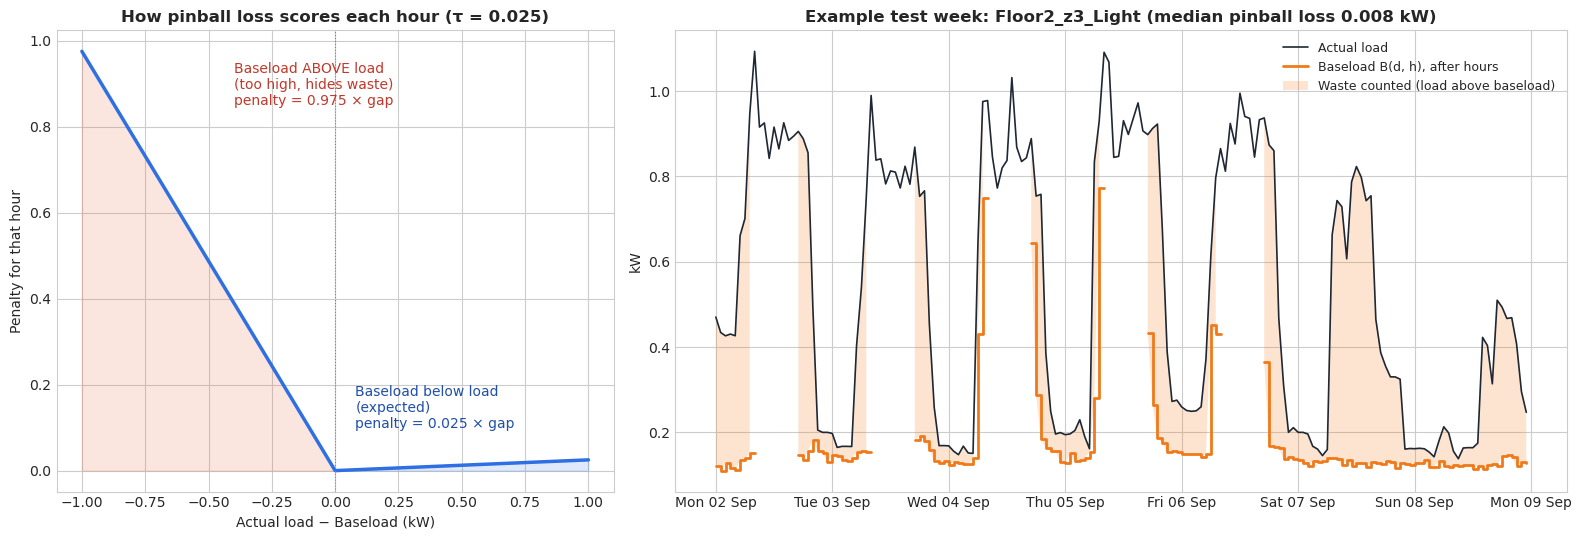

In [19]:
# ===== 12.1b PINBALL LOSS: VISUAL =====
# Left: the penalty shape. Right: one test week of a preventable circuit, actual load vs baseload.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 1.6]})

gap = np.linspace(-1, 1, 201)                                   # P - B (kW)
loss = np.maximum(BASELOAD_PERCENTILE * gap, (BASELOAD_PERCENTILE - 1) * gap)
ax1.plot(gap, loss, color='#2f6fe4', lw=2.5)
ax1.axvline(0, color='grey', lw=0.8, ls=':')
ax1.fill_between(gap, 0, loss, where=gap < 0, color='#e4572e', alpha=0.15)
ax1.fill_between(gap, 0, loss, where=gap >= 0, color='#2f6fe4', alpha=0.15)
ax1.text(-0.40, 0.95, 'Baseload ABOVE load\n(too high, hides waste)\npenalty = 0.975 × gap', color='#c0392b', fontsize=10, va='top')
ax1.text(0.08, 0.20, 'Baseload below load\n(expected)\npenalty = 0.025 × gap', color='#1f4fa8', fontsize=10, va='top')
ax1.set_xlabel('Actual load − Baseload (kW)'); ax1.set_ylabel('Penalty for that hour')
ax1.set_title('How pinball loss scores each hour (τ = 0.025)', fontweight='bold')

# Example: the preventable circuit with the median test pinball loss, one test week
def circuit_pinball(c):
    b = dynamic_base_matrix.reindex(dow_h(test))[c].to_numpy(); a = test[c].to_numpy()
    ok = ~np.isnan(a) & ~np.isnan(b); d = (a - b)[ok]
    return np.mean(np.maximum(BASELOAD_PERCENTILE * d, (BASELOAD_PERCENTILE - 1) * d))
pin_by_circuit = pd.Series({c: circuit_pinball(c) for c in cols}).sort_values()
ex = pin_by_circuit.index[len(pin_by_circuit) // 2]
wk = master_hourly.loc['2019-09-02':'2019-09-08', ex]
wk_base = dynamic_base_matrix.reindex(dow_h(wk))[ex].to_numpy()
unocc_wk = master_hourly.loc['2019-09-02':'2019-09-08', 'Is_Unoccupied'] == 1
ax2.plot(wk.index, wk.values, color='#1e2733', lw=1.2, label='Actual load')
ax2.step(wk.index, np.where(unocc_wk, wk_base, np.nan), where='post', color='#f07a1a', lw=2, label='Baseload B(d, h), after hours')
ax2.fill_between(wk.index, np.where(unocc_wk, wk_base, np.nan), np.where(unocc_wk, wk.values, np.nan),
                 color='#f07a1a', alpha=0.2, lw=0, label='Waste counted (load above baseload)')
ax2.set_title(f'Example test week: {ex.replace("(kW)", "")} (median pinball loss {pin_by_circuit[ex]:.3f} kW)', fontweight='bold')
ax2.set_ylabel('kW'); ax2.legend(loc='upper right', fontsize=9)
import matplotlib.dates as mdates
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b'))
plt.tight_layout(); plt.show()

#### 12.2 Sensitivity to the percentile

Re-run the annual waste (training year, Preventable Waste circuits) with the baseload set at P1, P2.5, P5 and P10.
If the total moves only modestly and the floor ranking stays the same, the conclusions do not depend on the exact percentile.

In [20]:
# ===== 12.2 SENSITIVITY: ANNUAL WASTE AT DIFFERENT PERCENTILES =====
train_unocc = unocc[unocc['Is_Train_Period'] == 1]
sens_rows = []
for q in [0.01, 0.025, 0.05, 0.10]:
    m = train_unocc_h.groupby([train_unocc_h.index.dayofweek, train_unocc_h.index.hour])[all_circuit_cols].quantile(q)
    base = m.reindex(dow_h(train_unocc))[cols]
    base = base.fillna(pd.Series({c: sunday_baseloads.get(c, 0.0) for c in cols}))   # same fallback as Section 7
    excess = (train_unocc[cols].to_numpy() - base.to_numpy()).clip(min=0)
    by_floor = pd.Series(np.nansum(excess, axis=0), index=cols).groupby(lambda c: c.split('_')[0]).sum()
    sens_rows.append({'Percentile': f"P{q*100:g}",
                      'Annual_Waste_MWh': round(float(np.nansum(excess)) / 1000, 1),
                      'Floor1_Share_%': round(by_floor['Floor1'] / by_floor.sum() * 100, 1),
                      'Floor_Ranking': ' > '.join(f.replace('Floor', 'F') for f in by_floor.sort_values(ascending=False).index)})
sens_df = pd.DataFrame(sens_rows)
ref = sens_df.loc[sens_df['Percentile'] == 'P2.5', 'Annual_Waste_MWh'].iloc[0]
sens_df['Change_vs_P2.5_%'] = ((sens_df['Annual_Waste_MWh'] / ref - 1) * 100).round(1)
display(sens_df)

,Percentile,Annual_Waste_MWh,Floor1_Share_%,Floor_Ranking,Change_vs_P2.5_%
0,P1,376.5,71.0,F1 > F6 > F7 > F5 > F4 > F3 > F2,6.3
1,P2.5,354.3,71.3,F1 > F6 > F7 > F5 > F4 > F3 > F2,0.0
2,P5,327.4,71.7,F1 > F6 > F7 > F5 > F4 > F3 > F2,-7.6
3,P10,280.8,72.9,F1 > F6 > F7 > F4 > F5 > F3 > F2,-20.7


**How to read sensitivity.** The baseload uses the 2.5th percentile, which is a choice. Sensitivity re-runs the waste estimate with other percentiles to check whether that choice changes the answer. A higher percentile gives a higher baseload and therefore less waste, so the total always falls as the percentile rises; what matters is whether the **conclusions** change.

| What happens | What it means |
| :--- | :--- |
| Total changes modestly, same floor ranking, same Floor 1 share | The findings do not depend on the exact percentile. |
| Floor ranking or the largest source of waste changes | The findings depend on the percentile, so the choice must be justified carefully. |

**Our result:** From P1 to P5 the total moves between +6.3% and −7.6% (376.5 → 327.4 MWh) and the floor ranking does not change. Even at P10 (−20.7%), Floor 1 is still the largest source at 71–73% of waste; only Floors 4 and 5 swap places. The conclusions (where the waste is and which floor to act on first) hold for any reasonable percentile. The 354.3 MWh headline is best read as a central estimate within roughly 330–375 MWh.

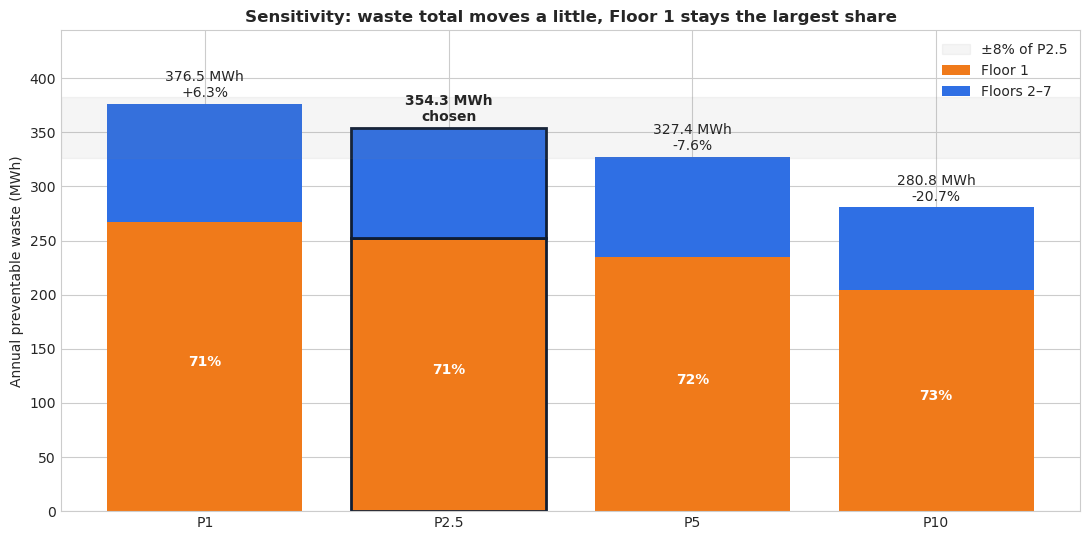

In [21]:
# ===== 12.2b SENSITIVITY: VISUAL =====
floor_rows = []
for q in [0.01, 0.025, 0.05, 0.10]:
    m = train_unocc_h.groupby([train_unocc_h.index.dayofweek, train_unocc_h.index.hour])[all_circuit_cols].quantile(q)
    base = m.reindex(dow_h(train_unocc))[cols].fillna(pd.Series({c: sunday_baseloads.get(c, 0.0) for c in cols}))
    ex_kwh = pd.Series(np.nansum((train_unocc[cols].to_numpy() - base.to_numpy()).clip(min=0), axis=0), index=cols)
    f = ex_kwh.groupby(lambda c: c.split('_')[0]).sum() / 1000
    floor_rows.append({'Percentile': f"P{q*100:g}", 'Floor 1': f['Floor1'], 'Floors 2–7': f.drop('Floor1').sum()})
fs = pd.DataFrame(floor_rows).set_index('Percentile')

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(fs))
edge = ['#0f1d33' if p == 'P2.5' else 'none' for p in fs.index]
ax.bar(x, fs['Floor 1'], color='#f07a1a', label='Floor 1', edgecolor=edge, lw=2)
ax.bar(x, fs['Floors 2–7'], bottom=fs['Floor 1'], color='#2f6fe4', label='Floors 2–7', edgecolor=edge, lw=2)
tot = fs.sum(axis=1)
for i, (p, t) in enumerate(tot.items()):
    chg = (t / tot['P2.5'] - 1) * 100
    ax.text(i, t + 6, f"{t:.1f} MWh\n{'chosen' if p == 'P2.5' else f'{chg:+.1f}%'}", ha='center', fontsize=10, fontweight='bold' if p == 'P2.5' else 'normal')
    ax.text(i, fs.loc[p, 'Floor 1'] / 2, f"{fs.loc[p, 'Floor 1'] / t * 100:.0f}%", ha='center', color='white', fontweight='bold')
ax.axhspan(tot['P2.5'] * 0.92, tot['P2.5'] * 1.08, color='grey', alpha=0.08, label='±8% of P2.5')
ax.set_xticks(x, fs.index); ax.set_ylabel('Annual preventable waste (MWh)')
ax.set_ylim(0, tot.max() * 1.18)
ax.set_title('Sensitivity: waste total moves a little, Floor 1 stays the largest share', fontweight='bold')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

#### 12.3 Coverage per circuit and by hour

The overall figure can hide circuits or hours where the baseload is too high. Below, coverage on the unseen test window is
broken down per Preventable Waste circuit and per hour of day.

In [22]:
# ===== 12.3 COVERAGE PER CIRCUIT AND BY HOUR (TEST WINDOW) =====
test_base = dynamic_base_matrix.reindex(dow_h(test))[cols].to_numpy()
test_act  = test[cols].to_numpy()
test_ok   = ~np.isnan(test_act) & ~np.isnan(test_base)
above     = np.where(test_ok, test_act >= test_base, np.nan)

per_circuit = pd.Series(np.nanmean(above, axis=0), index=cols).mul(100).round(1).sort_values()
print(f"Per-circuit test coverage: median {per_circuit.median():.1f}%, "
      f"{(per_circuit < 95).sum()} of {len(per_circuit)} circuits below 95%")
display(per_circuit[per_circuit < 95].rename('Test_Coverage_%').to_frame())

by_hour = pd.DataFrame(above, index=test.index).groupby(test.index.hour).apply(lambda d: np.nanmean(d.to_numpy()) * 100)
by_hour = by_hour.round(1).rename('Test_Coverage_%').to_frame()
by_hour['Hours_of_Data'] = test.groupby(test.index.hour).size()
display(by_hour.T)

Per-circuit test coverage: median 99.1%, 8 of 59 circuits below 95%


,Test_Coverage_%
Floor1_z1_Plug(kW),39.6
Floor7_z1_Plug(kW),77.4
Floor4_z1_Light(kW),87.0
Floor4_z2_Plug(kW),90.2
Floor2_z1_Light(kW),93.3
Floor3_z3_Light(kW),94.3
Floor1_z4_Light(kW),94.7
Floor7_z2_Plug(kW),94.8


Date,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Test_Coverage_%,97.5,97.4,97.1,97.2,97.3,97.3,96.4,95.9,95.3,95.5,...,95.6,95.3,95.3,96.4,97.0,97.0,97.4,97.5,97.3,97.2
Hours_of_Data,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,61.0,61.0,...,61.0,61.0,61.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0


#### 12.4 Data per slot

Each `(day, hour)` slot's P2.5 comes from the training hours in that slot. Slots with few hours (weekday daytime slots,
which are only after-hours on public holidays) give a less reliable 2.5th percentile.

In [23]:
# ===== 12.4 TRAINING HOURS PER (DAY, HOUR) SLOT =====
slot_n = train_unocc_h.groupby([train_unocc_h.index.dayofweek, train_unocc_h.index.hour]).size()
slot_n.index.names = ['DayOfWeek', 'Hour']
thin = slot_n[slot_n < 15]
print(f"{len(slot_n)} after-hours slots; median {slot_n.median():.0f} training hours per slot; "
      f"{len(thin)} slots with fewer than 15 hours")
display(thin.rename('Training_Hours').reset_index().groupby('DayOfWeek')['Hour']
        .agg(lambda h: f"{h.min():02d}:00–{h.max():02d}:00 ({len(h)} slots)").to_frame('Thin_Slots'))

159 after-hours slots; median 52 training hours per slot; 36 slots with fewer than 15 hours


,Thin_Slots
DayOfWeek,
0,08:00–16:00 (9 slots)
1,08:00–16:00 (9 slots)
2,08:00–16:00 (9 slots)
4,08:00–16:00 (9 slots)


---

### Executive Summary & Deliverables Alignment

| Project Dimension | Analytical Finding / Deliverable | Strategic Management Implication |
| :--- | :--- | :--- |
| **Operating Boundary** | **Mon–Fri 08:00–17:00** (Stable across years) | Clear physical demarcation between occupied surge (+85 kW) and unoccupied curfew hours. |
| **Reference Calibration Window** | **Sundays 02:00–04:00 AM** | Lowest-occupancy, most stable overnight window (~79.0 kW), capturing steady-state baseload. |
| **Baseload Architecture** | **Dynamic Time-of-Week $P_{2.5}(d, h)$** | Dynamic 168-hour baseload accommodates natural departure gradients while preserving quiescent floors. |
| **Deliverable 01: Waste Map** | **Generated Heatmap (Floors 1–7)** | Floor 1 facade/atrium lighting drives ~58% of evening load; upper-floor lighting left on adds ~26%. |
| **Deliverable 02: Classification** | **6 Critical Standby / 59 Preventable Waste** | K-Means ($k=3$, silhouette 0.43) on five behaviour features separates 24/7 loads (engine room, stair-hall plugs) from scheduled (16) and occupancy-following (43) loads. |
| **Annual Preventable Energy** | **354,264 kWh / year** (theoretical maximum) | 12-month dynamic baseload; 65% from Floor 1 lighting, whose realistic share depends on the chosen schedule. |
| **Annual Utility Cost Avoidance** | **฿1,124,753 / year** (excl. VAT)<br>**฿1,203,485 / year** (incl. 7% VAT) | Direct cash savings potential via automated BEMS curfew sweeps (MEA Schedule 4.2 TOU; rates to be confirmed against MEA’s current 12–24 kV table). |
| **Model Generalization (Test Set)** | **−6.0% (complete floors)**<br>−7.4% incl. truncated Floor 6 | Like-for-like Jul–Dec 2019 holdout vs. Jul–Dec 2018 shows a similar level of surplus a year later. |
| **Baseload Coverage Check** | **97.4% (Train) / 96.8% (Test)** vs. 97.5% target | Actual after-hours load sits above the $P_{2.5}(d, h)$ floor at the expected quantile rate on unseen data. |
| **Digital Twin Transfer** | **`qn1_dynamic_baseload_matrix.csv`** | Direct synchronization with building 3D model and savings simulator webapp. |
